# Affinity Predictor Evaluation

## Imports

In [1]:
import json
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torch.utils.data import DataLoader, Dataset

from models.predictor_model import AffinityPredictor, predict
from helpers import create_model_name

# Teammate inputs: Task 2 metric definitions, so every model is scored identically
sys.path.insert(0, os.path.abspath(os.path.join("..", "task2")))
from utils.evaluation import concordance_index, hit_at_k, mean_squared_error

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", DEVICE)

Using: cuda


## Config

In [2]:
PROJECT_ROOT = os.path.abspath("..")

# Inputs, written by prepare_data.ipynb
DATA_DIR = os.path.join(PROJECT_ROOT, "open_task", "data")
DRUG_EMBEDDING_FILE = os.path.join(DATA_DIR, "drug_embedding.npy")
PROTEIN_EMBEDDING_FILE = os.path.join(DATA_DIR, "protein_embedding.npy")
DRUG_MAPPING_FILE = os.path.join(DATA_DIR, "drug_mapping.csv")
PROTEIN_MAPPING_FILE = os.path.join(DATA_DIR, "protein_mapping.csv")
SPLIT_PATTERN = os.path.join(DATA_DIR, "protein-holdout-{holdout}", "{dataset}_{split}.csv")
DRUG_ID_COLUMN = "drug_id"
PROTEIN_ID_COLUMN = "protein_id"
SMILES_COLUMN = "compound_iso_smiles"
SEQUENCE_COLUMN = "target_sequence"
AFFINITY_COLUMN = "affinity"
PREDICTION_COLUMN = "prediction"
FALLBACK_COLUMN = "fallback"
COLD_COLUMN = "cold"
SPLITS = ("val", "test")
TRAIN_SPLIT = "train"

# One model per dataset: pKd and the transformed KIBA score are different quantities
DATASETS = ["kiba", "davis"]

# Holdouts to evaluate; every model must have been fitted on each of them
HOLDOUTS = [0.0, 0.1, 0.2, 0.3, 0.5, 0.75]

# Teammate input: biased MF cannot be refitted on a holdout, because it raises on an
# unseen target, so its own validation numbers appear only at holdout 0.0
BIASED_MF_PATTERN = os.path.join(
    PROJECT_ROOT, "task2", "saved_models", "{dataset}_biased_mf.npz")
BIASED_MF_SPLIT = "val"
BIASED_MF_HOLDOUT = 0.0

BATCH_SIZE = 1024
HIT_K = (1, 5)

# Inputs, written by train_predictor.ipynb and CF_baselines.ipynb
MODEL_PATTERN = os.path.join(
    PROJECT_ROOT, "open_task", "models", "saved_models", "predictor_{name}.pt")
PREDICTION_PATTERN = os.path.join(
    PROJECT_ROOT, "open_task", "predictions", "{model}_{name}_{split}.csv")

# Outputs
FIGURE_DIR = os.path.join(PROJECT_ROOT, "open_task", "figures")
CURVE_PATTERN = os.path.join(FIGURE_DIR, "curves_{split}_{group}.png")
PANEL_PATTERN = os.path.join(FIGURE_DIR, "curve_{split}_{group}_{dataset}_{metric}.png")
FOCUS_PATTERN = os.path.join(FIGURE_DIR, "focus_{name}_{split}_{group}.png")

os.makedirs(FIGURE_DIR, exist_ok=True)

# The best four-hue set the palette offers: normal-vision separation 20.8 against a floor
# of 15, worst colour-vision separation 7.5, which the 6-8 band allows only alongside a
# second channel, so each base model also carries its own marker
PREDICTOR_COLOR = "#2a78d6"
DRUG_CF_COLOR = "#e34948"
PROTEIN_CF_COLOR = "#1baf7a"
BIASED_MF_COLOR = "#eda100"
TEXT_COLOR = "#0b0b0b"
MUTED_COLOR = "#52514e"
GRID_COLOR = "#e5e4e0"

pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

## Embeddings

In [3]:
drug_vectors = torch.from_numpy(np.load(DRUG_EMBEDDING_FILE)).to(DEVICE)
protein_vectors = torch.from_numpy(np.load(PROTEIN_EMBEDDING_FILE)).to(DEVICE)

display(pd.DataFrame(
    [
        {"entity": "drug", "rows": drug_vectors.shape[0], "dim": drug_vectors.shape[1]},
        {"entity": "protein", "rows": protein_vectors.shape[0], "dim": protein_vectors.shape[1]},
    ]
).set_index("entity"))

,rows,dim
entity,,
drug,2127,768
protein,429,320


## Splits

In [4]:
class PairDataset(Dataset):
    def __init__(self, frame):
        self.drug_ids = torch.tensor(frame[DRUG_ID_COLUMN].to_numpy(), dtype=torch.long)
        self.protein_ids = torch.tensor(frame[PROTEIN_ID_COLUMN].to_numpy(), dtype=torch.long)
        self.affinities = torch.tensor(frame[AFFINITY_COLUMN].to_numpy(), dtype=torch.float32)

    def __len__(self):
        return len(self.affinities)

    def __getitem__(self, index):
        return self.drug_ids[index], self.protein_ids[index], self.affinities[index]


# keep_default_na=False so a SMILES like NA stays a string
drug_mapping = pd.read_csv(DRUG_MAPPING_FILE, keep_default_na=False)
protein_mapping = pd.read_csv(PROTEIN_MAPPING_FILE, keep_default_na=False)
smiles = dict(zip(drug_mapping[DRUG_ID_COLUMN], drug_mapping[SMILES_COLUMN]))
sequences = dict(zip(protein_mapping[PROTEIN_ID_COLUMN], protein_mapping[SEQUENCE_COLUMN]))


def read_split(dataset, holdout, split):
    """One holdout split, with the text columns Hit@K ranks on."""
    frame = pd.read_csv(SPLIT_PATTERN.format(dataset=dataset, holdout=holdout, split=split))
    frame[SMILES_COLUMN] = frame[DRUG_ID_COLUMN].map(smiles)
    frame[SEQUENCE_COLUMN] = frame[PROTEIN_ID_COLUMN].map(sequences)
    return frame


frames = {}
for dataset in DATASETS:
    for holdout in HOLDOUTS:
        # A protein absent from this training split is cold for every model alike
        trained = set(read_split(dataset, holdout, TRAIN_SPLIT)[PROTEIN_ID_COLUMN])
        for split in SPLITS:
            frame = read_split(dataset, holdout, split)
            frame[COLD_COLUMN] = ~frame[PROTEIN_ID_COLUMN].isin(trained)
            frames[dataset, holdout, split] = frame

loaders = {
    key: DataLoader(PairDataset(frame), batch_size=BATCH_SIZE)
    for key, frame in frames.items()
}

display(pd.DataFrame(
    [
        {
            "dataset": dataset,
            "holdout": holdout,
            "split": split,
            "pairs": len(frame),
            "cold rows": int(frame[COLD_COLUMN].sum()),
        }
        for (dataset, holdout, split), frame in frames.items()
    ]
).set_index(["dataset", "holdout", "split"]))

pairs  cold rows
dataset holdout split                  
kiba    0.0000  val    17648          0
                test   17650          0
        0.1000  val    17648       1766
                test   17650       1849
        0.2000  val    17648       3711
                test   17650       3854
        0.3000  val    17648       5196
                test   17650       5359
        0.5000  val    17648       8346
                test   17650       8412
        0.7500  val    17648      12887
                test   17650      12979
davis   0.0000  val     3865          0
                test    3867          0
        0.1000  val     3865        380
                test    3867        389
        0.2000  val     3865        766
                test    3867        796
        0.3000  val     3865       1139
                test    3867       1213
        0.5000  val     3865       1933
                test    3867       1968
        0.7500  val     3865       2870
                test    3867       2913

## Model

In [5]:
models = {}
loaded = []

for dataset in DATASETS:
    for holdout in HOLDOUTS:
        model_file = MODEL_PATTERN.format(name=create_model_name(dataset, holdout))
        state = torch.load(model_file, map_location=DEVICE)

        weights = [key for key in state if key.startswith("mlp.") and key.endswith("weight")]
        hidden_sizes = [state[key].shape[0] for key in weights[:-1]]

        model = AffinityPredictor(drug_vectors, protein_vectors, hidden_sizes, dropout=0.0).to(DEVICE)
        model.load_state_dict(state)
        model.eval()
        models[dataset, holdout] = model

        loaded.append({
            "dataset": dataset,
            "holdout": holdout,
            "checkpoint": os.path.basename(model_file),
            "hidden sizes": str(tuple(hidden_sizes)),
        })

display(pd.DataFrame(loaded).set_index(["dataset", "holdout"]))

checkpoint     hidden sizes
dataset holdout                                                  
kiba    0.0000     predictor_kiba_holdout_0.0.pt  (512, 256, 256)
        0.1000     predictor_kiba_holdout_0.1.pt  (512, 256, 256)
        0.2000     predictor_kiba_holdout_0.2.pt  (512, 256, 256)
        0.3000     predictor_kiba_holdout_0.3.pt  (512, 256, 256)
        0.5000     predictor_kiba_holdout_0.5.pt  (512, 256, 256)
        0.7500    predictor_kiba_holdout_0.75.pt  (512, 256, 256)
davis   0.0000    predictor_davis_holdout_0.0.pt  (512, 256, 256)
        0.1000    predictor_davis_holdout_0.1.pt  (512, 256, 256)
        0.2000    predictor_davis_holdout_0.2.pt  (512, 256, 256)
        0.3000    predictor_davis_holdout_0.3.pt  (512, 256, 256)
        0.5000    predictor_davis_holdout_0.5.pt  (512, 256, 256)
        0.7500   predictor_davis_holdout_0.75.pt  (512, 256, 256)

## Predictions

In [6]:
MODEL_NAME = "AffinityPredictor"
BIASED_MF_NAME = "biased MF (task 2)"
LABELS = {
    "global_mean": "global mean",
    "drug_cf": "drug CF",
    "protein_cf": "protein CF",
    "biased_mf": "biased MF",
}


def read_saved(model, dataset, holdout, split, frame):
    """Predictions written by another notebook, aligned to this frame by pair keys."""
    path = PREDICTION_PATTERN.format(
        model=model, name=create_model_name(dataset, holdout), split=split)
    saved = pd.read_csv(path)
    return frame[[DRUG_ID_COLUMN, PROTEIN_ID_COLUMN]].merge(
        saved, on=[DRUG_ID_COLUMN, PROTEIN_ID_COLUMN], how="left")


predictions = {}
fallbacks = []

for (dataset, holdout, split), frame in frames.items():
    predicted, _ = predict(models[dataset, holdout], loaders[dataset, holdout, split], DEVICE)

    row = {MODEL_NAME: predicted}

    for baseline, label in LABELS.items():
        saved = read_saved(baseline, dataset, holdout, split, frame)
        row[label] = saved[PREDICTION_COLUMN].to_numpy()

        # Where CF found no usable neighbour it returned a mean; the predictor fills those
        if baseline != "global_mean":
            fallback = saved[FALLBACK_COLUMN].to_numpy()
            row[f"{label} + predictor"] = np.where(fallback, predicted, row[label])
            fallbacks.append({
                "dataset": dataset,
                "holdout": holdout,
                "split": split,
                "model": label,
                "cold rows": int(frame[COLD_COLUMN].sum()),
                "fallback rows": int(fallback.sum()),
            })

    predictions[dataset, holdout, split] = row

display(pd.DataFrame(fallbacks).set_index(["dataset", "holdout", "split", "model"]))

cold rows  fallback rows
dataset holdout split model                               
kiba    0.0000  val   drug CF             0            449
                      protein CF          0              1
                      biased MF           0              0
                test  drug CF             0            396
                      protein CF          0              0
                      biased MF           0              0
        0.1000  val   drug CF          1766           2164
                      protein CF       1766           1767
                      biased MF        1766           1766
                test  drug CF          1849           2196
                      protein CF       1849           1849
                      biased MF        1849           1849
        0.2000  val   drug CF          3711           4081
                      protein CF       3711           3713
                      biased MF        3711           3711
                test  drug CF          3854           4178
                      protein CF       3854           3854
                      biased MF        3854           3854
        0.3000  val   drug CF          5196           5578
                      protein CF       5196           5198
                      biased MF        5196           5196
                test  drug CF          5359           5694
                      protein CF       5359           5359
                      biased MF        5359           5359
        0.5000  val   drug CF          8346           8706
                      protein CF       8346           8367
                      biased MF        8346           8346
                test  drug CF          8412           8753
                      protein CF       8412           8423
                      biased MF        8412           8412
        0.7500  val   drug CF         12887          13305
                      protein CF      12887          12924
                      biased MF       12887          12911
                test  drug CF         12979          13411
                      protein CF      12979          13009
                      biased MF       12979          12995
davis   0.0000  val   drug CF             0              0
                      protein CF          0              0
                      biased MF           0              0
                test  drug CF             0              0
                      protein CF          0              0
                      biased MF           0              0
        0.1000  val   drug CF           380            380
                      protein CF        380            380
                      biased MF         380            380
                test  drug CF           389            389
                      protein CF        389            389
                      biased MF         389            389
        0.2000  val   drug CF           766            766
                      protein CF        766            766
                      biased MF         766            766
                test  drug CF           796            796
                      protein CF        796            796
                      biased MF         796            796
        0.3000  val   drug CF          1139           1139
                      protein CF       1139           1139
                      biased MF        1139           1139
                test  drug CF          1213           1213
                      protein CF       1213           1213
                      biased MF        1213           1213
        0.5000  val   drug CF          1933           1980
                      protein CF       1933           1933
                      biased MF        1933           1933
                test  drug CF          1968           2022
                      protein CF       1968           1968
                      biased MF        1968           1968
        0.7500  val   

## Metrics

In [7]:
def error_metrics(frame, predicted):
    """Per-row scores, unaffected by which other rows are present."""
    mse = mean_squared_error(frame[AFFINITY_COLUMN], predicted)
    return {
        "MSE": mse,
        "RMSE": mse ** 0.5,
        "CI": concordance_index(frame[AFFINITY_COLUMN], predicted),
    }


def query_eligibility(frame, query_column):
    """Per K, the queries Hit@K can actually test.

    A query with at most K candidates has all of them in its own top K, so it hits for
    any model at all and measures nothing. This is Task 2's restricted Hit@5 rule, kept
    as is so the numbers compare; queries whose candidates all tie on actual score stay
    in and hit for every model.
    """
    counts = frame.groupby(query_column)[AFFINITY_COLUMN].transform("size").to_numpy()
    return {k: counts > k for k in HIT_K}


def ranking_metrics(frame, predicted, query_column=SMILES_COLUMN,
                    candidate_column=SEQUENCE_COLUMN):
    """Hit@K over the rows given, so slicing to cold rows asks about new targets only.

    Task 2.3 asks whether a model can tell a ligand's unseen targets apart, so the best
    of those unseen targets is the intended answer. Ineligible queries drop out whole,
    which leaves every surviving query its own candidates and its own best.
    """
    eligible = query_eligibility(frame, query_column)
    return {
        f"Hit@{k}": hit_at_k(
            frame[selected],
            predicted[selected],
            k=k,
            drug_col=query_column,
            target_col=candidate_column,
            score_col=AFFINITY_COLUMN,
        )["hit_rate"]
        for k, selected in eligible.items()
    }


def reference_metrics(frame, predicted):
    """Task 2.2 as published: every ligand counted, no eligibility filter."""
    row = error_metrics(frame, predicted)

    for k in HIT_K:
        row[f"Hit@{k}"] = hit_at_k(
            frame,
            predicted,
            k=k,
            drug_col=SMILES_COLUMN,
            target_col=SEQUENCE_COLUMN,
            score_col=AFFINITY_COLUMN,
        )["hit_rate"]

    return row


def biased_mf_metrics(dataset):
    saved = np.load(BIASED_MF_PATTERN.format(dataset=dataset), allow_pickle=True)
    mse = float(saved["metric_val_mse"])
    row = {"MSE": mse, "RMSE": mse ** 0.5, "CI": float(saved["metric_val_ci"])}

    for k in HIT_K:
        row[f"Hit@{k}"] = float(saved[f"metric_val_hit_at_{k}"])

    return row

## Query coverage

In [8]:
# How many ligands each Hit@K column actually tests, before any model is involved
coverage = []

for (dataset, holdout, split), frame in frames.items():
    cold = frame[COLD_COLUMN].to_numpy()

    for group, selected in (
        ("all rows", np.ones(len(frame), dtype=bool)),
        ("warm rows", ~cold),
        ("cold rows", cold),
    ):
        subset = frame[selected]
        if not len(subset):
            continue

        coverage.append({
            "dataset": dataset,
            "holdout": holdout,
            "split": split,
            "group": group,
            "ligands": subset[SMILES_COLUMN].nunique(),
            "median targets": subset.groupby(SMILES_COLUMN)[SEQUENCE_COLUMN].size().median(),
            **{
                f"testable@{k}": subset[eligible][SMILES_COLUMN].nunique()
                for k, eligible in query_eligibility(subset, SMILES_COLUMN).items()
            },
        })

display(pd.DataFrame(coverage).set_index(["dataset", "holdout", "split", "group"]))

ligands  median targets  testable@1  \
dataset holdout split group                                            
kiba    0.0000  val   all rows      1967          6.0000        1719   
                      warm rows     1967          6.0000        1719   
                test  all rows      1951          6.0000        1707   
                      warm rows     1951          6.0000        1707   
        0.1000  val   all rows      1967          6.0000        1719   
                      warm rows     1932          5.0000        1651   
                      cold rows     1034          1.0000         456   
                test  all rows      1951          6.0000        1707   
                      warm rows     1917          5.0000        1625   
                      cold rows     1055          1.0000         499   
        0.2000  val   all rows      1967          6.0000        1719   
                      warm rows     1899          5.0000        1588   
                      cold rows     1396          2.0000         898   
                test  all rows      1951          6.0000        1707   
                      warm rows     1891          5.0000        1541   
                      cold rows     1388          2.0000         930   
        0.3000  val   all rows      1967          6.0000        1719   
                      warm rows     1878          4.0000        1539   
                      cold rows     1519          3.0000        1071   
                test  all rows      1951          6.0000        1707   
                      warm rows     1869          4.0000        1508   
                      cold rows     1503          3.0000        1062   
        0.5000  val   all rows      1967          6.0000        1719   
                      warm rows     1774          4.0000        1370   
                      cold rows     1697          4.0000        1322   
                test  all rows      1951          6.0000        1707   
                      warm rows     1779          4.0000        1362   
                      cold rows     1688          4.0000        1271   
        0.7500  val   all rows      1967          6.0000        1719   
                      warm rows     1437          2.0000         972   
                      cold rows     1863          5.0000        1544   
                test  all rows      1951          6.0000        1707   
                      warm rows     1462          2.0000         957   
                      cold rows     1854          5.0000        1528   
davis   0.0000  val   all rows        68         57.5000          68   
                      warm rows       68         57.5000          68   
                test  all rows        68         57.0000          68   
                      warm rows       68         57.0000          68   
        0.1000  val   all rows        68         57.5000          68   
                      warm rows       68         51.0000          68   
                      cold rows       68          5.0000          68   
                test  all rows        68         57.0000          68   
                      warm rows       68         51.0000          68   
                      cold rows       68          6.0000          68   
        0.2000  val   all rows        68         57.5000          68   
                      warm rows       68         46.0000          68   
                      cold rows       68         11.0000          68   
                test  all rows        68         57.0000          68   
                      warm rows       68         45.0000          68   
                      cold rows       68         12.0000          68   
        0.3000  val   all rows        68         57.5000          68   
                      warm rows       68         40.5000          68   
                      cold rows       68         17.0000          68   
                test  all rows        68         57.0000          68   
 

## Task 2 reproduction

In [9]:
# Ligand as query at holdout 0.0, the one configuration Task 2's own numbers cover
for dataset in DATASETS:
    frame = frames[dataset, BIASED_MF_HOLDOUT, BIASED_MF_SPLIT]
    rows = [
        {"model": name, **reference_metrics(frame, predicted)}
        for name, predicted in predictions[dataset, BIASED_MF_HOLDOUT, BIASED_MF_SPLIT].items()
    ]
    rows.append({"model": BIASED_MF_NAME, **biased_mf_metrics(dataset)})

    print(f"{dataset} / {BIASED_MF_SPLIT} / holdout {BIASED_MF_HOLDOUT} / ligand as query")
    display(pd.DataFrame(rows).set_index("model"))

kiba / val / holdout 0.0 / ligand as query


,MSE,RMSE,CI,Hit@1,Hit@5
model,,,,,
AffinityPredictor,0.2822,0.5312,0.7955,0.5862,0.8907
global mean,0.6878,0.8293,0.5000,0.3757,0.7178
drug CF,0.2090,0.4572,0.8489,0.6660,0.9349
drug CF + predictor,0.2095,0.4577,0.8480,0.6736,0.9365
protein CF,0.2398,0.4897,0.8265,0.6202,0.9217
protein CF + predictor,0.2396,0.4895,0.8266,0.6202,0.9217
biased MF,0.1888,0.4345,0.8481,0.6904,0.9522
biased MF + predictor,0.1888,0.4345,0.8481,0.6904,0.9522
biased MF (task 2),0.1888,0.4345,0.8481,0.6904,0.9522


davis / val / holdout 0.0 / ligand as query


,MSE,RMSE,CI,Hit@1,Hit@5
model,,,,,
AffinityPredictor,0.3476,0.5896,0.8405,0.2500,0.5147
global mean,0.6751,0.8217,0.5000,0.1029,0.1324
drug CF,0.3230,0.5683,0.8561,0.3088,0.6765
drug CF + predictor,0.3230,0.5683,0.8561,0.3088,0.6765
protein CF,0.2827,0.5317,0.8661,0.3235,0.6471
protein CF + predictor,0.2827,0.5317,0.8661,0.3235,0.6471
biased MF,0.2598,0.5097,0.8732,0.3382,0.7206
biased MF + predictor,0.2598,0.5097,0.8732,0.3382,0.7206
biased MF (task 2),0.2598,0.5097,0.8732,0.3382,0.7206


## Comparison

In [10]:
GROUPS = ("all rows", "warm rows", "cold rows")

# One table per dataset, split and row group, with every holdout stacked so trends read
# downwards. Hit@K is the ligand's view, so the cold group asks Task 2.3's question:
# among this ligand's unseen targets, does the model rank the best one first?
measurements = []

for dataset in DATASETS:
    for split in SPLITS:
        for group in GROUPS:
            rows = []

            for holdout in HOLDOUTS:
                frame = frames[dataset, holdout, split]
                cold = frame[COLD_COLUMN].to_numpy()

                # Without cold rows the warm group is all rows again, kept so warm curves
                # start at 0.0; the cold group is empty and has nothing to score
                if group == "cold rows" and not cold.any():
                    continue
                selected = {
                    "all rows": np.ones(len(frame), dtype=bool),
                    "warm rows": ~cold,
                    "cold rows": cold,
                }[group]
                subset = frame[selected]

                rows += [
                    {
                        "holdout": holdout,
                        "model": name,
                        **error_metrics(subset, predicted[selected]),
                        **ranking_metrics(subset, predicted[selected]),
                    }
                    for name, predicted in predictions[dataset, holdout, split].items()
                ]

            measurements += [
                {"dataset": dataset, "split": split, "group": group, **row} for row in rows
            ]

            print(f"{dataset} / {split} / {group}")
            display(pd.DataFrame(rows).set_index(["holdout", "model"]))

kiba / val / all rows


MSE   RMSE     CI  Hit@1  Hit@5
holdout model                                                    
0.0000  AffinityPredictor      0.2822 0.5312 0.7955 0.5265 0.7867
        global mean            0.6878 0.8293 0.5000 0.2856 0.4494
        drug CF                0.2090 0.4572 0.8489 0.6178 0.8730
        drug CF + predictor    0.2095 0.4577 0.8480 0.6265 0.8760
        protein CF             0.2398 0.4897 0.8265 0.5654 0.8472
        protein CF + predictor 0.2396 0.4895 0.8266 0.5654 0.8472
        biased MF              0.1888 0.4345 0.8481 0.6457 0.9067
        biased MF + predictor  0.1888 0.4345 0.8481 0.6457 0.9067
0.1000  AffinityPredictor      0.2557 0.5056 0.8041 0.5346 0.7996
        global mean            0.6879 0.8294 0.5000 0.2856 0.4494
        drug CF                0.2295 0.4790 0.8382 0.5939 0.8383
        drug CF + predictor    0.2259 0.4753 0.8361 0.5939 0.8462
        protein CF             0.2969 0.5449 0.8006 0.5433 0.8155
        protein CF + predictor 0.2565 0.5065 0.8163 0.5486 0.8264
        biased MF              0.2148 0.4634 0.8363 0.6155 0.8770
        biased MF + predictor  0.2111 0.4595 0.8348 0.6149 0.8889
0.2000  AffinityPredictor      0.3198 0.5655 0.7726 0.4933 0.7470
        global mean            0.6878 0.8293 0.5000 0.2856 0.4494
        drug CF                0.2538 0.5038 0.8236 0.5782 0.8145
        drug CF + predictor    0.2603 0.5102 0.8145 0.5753 0.8175
        protein CF             0.3493 0.5910 0.7704 0.5230 0.7679
        protein CF + predictor 0.2917 0.5401 0.7951 0.5305 0.7827
        biased MF              0.2444 0.4943 0.8219 0.5788 0.8204
        biased MF + predictor  0.2502 0.5002 0.8128 0.5643 0.8244
0.3000  AffinityPredictor      0.3288 0.5734 0.7689 0.4770 0.7391
        global mean            0.6878 0.8294 0.5000 0.2856 0.4494
        drug CF                0.2717 0.5212 0.8108 0.5538 0.7688
        drug CF + predictor    0.2905 0.5390 0.7988 0.5433 0.7738
        protein CF             0.3812 0.6174 0.7483 0.4887 0.7262
        protein CF + predictor 0.3184 0.5643 0.7817 0.4834 0.7381
        biased MF              0.2615 0.5113 0.8083 0.5666 0.7778
        biased MF + predictor  0.2804 0.5295 0.7960 0.5462 0.7817
0.5000  AffinityPredictor      0.3533 0.5944 0.7500 0.4474 0.7183
        global mean            0.6883 0.8297 0.5000 0.2856 0.4494
        drug CF                0.3162 0.5623 0.7803 0.4997 0.7143
        drug CF + predictor    0.3313 0.5756 0.7681 0.4951 0.7371
        protein CF             0.4600 0.6782 0.6900 0.4514 0.6607
        protein CF + predictor 0.3519 0.5932 0.7572 0.4578 0.7163
        biased MF              0.3080 0.5550 0.7776 0.5044 0.7113
        biased MF + predictor  0.3229 0.5683 0.7648 0.4857 0.7302
0.7500  AffinityPredictor      0.4451 0.6671 0.7106 0.3880 0.6349
        global mean            0.6877 0.8293 0.5000 0.2856 0.4494
        drug CF                0.4091 0.6396 0.7352 0.3973 0.5724
        drug CF + predictor    0.4381 0.6619 0.7178 0.4008 0.6468
        protein CF             0.5738 0.7575 0.6079 0.3828 0.5516
        protein CF + predictor 0.4420 0.6648 0.7144 0.3997 0.6300
        biased MF              0.4092 0.6397 0.7318 0.3706 0.5625
        biased MF + predictor  0.4375 0.6615 0.7143 0.3845 0.6409

kiba / val / warm rows


MSE   RMSE     CI  Hit@1  Hit@5
holdout model                                                    
0.0000  AffinityPredictor      0.2822 0.5312 0.7955 0.5265 0.7867
        global mean            0.6878 0.8293 0.5000 0.2856 0.4494
        drug CF                0.2090 0.4572 0.8489 0.6178 0.8730
        drug CF + predictor    0.2095 0.4577 0.8480 0.6265 0.8760
        protein CF             0.2398 0.4897 0.8265 0.5654 0.8472
        protein CF + predictor 0.2396 0.4895 0.8266 0.5654 0.8472
        biased MF              0.1888 0.4345 0.8481 0.6457 0.9067
        biased MF + predictor  0.1888 0.4345 0.8481 0.6457 0.9067
0.1000  AffinityPredictor      0.2476 0.4976 0.8103 0.5482 0.8181
        global mean            0.6832 0.8265 0.5000 0.2738 0.4532
        drug CF                0.2145 0.4631 0.8468 0.6154 0.8759
        drug CF + predictor    0.2145 0.4632 0.8458 0.6233 0.8770
        protein CF             0.2487 0.4987 0.8236 0.5742 0.8580
        protein CF + predictor 0.2486 0.4986 0.8236 0.5742 0.8580
        biased MF              0.1981 0.4451 0.8445 0.6323 0.9211
        biased MF + predictor  0.1981 0.4451 0.8445 0.6323 0.9211
0.2000  AffinityPredictor      0.2990 0.5468 0.7919 0.5302 0.8261
        global mean            0.6922 0.8320 0.5000 0.2764 0.4794
        drug CF                0.2228 0.4721 0.8450 0.6228 0.8941
        drug CF + predictor    0.2236 0.4729 0.8439 0.6291 0.8963
        protein CF             0.2636 0.5134 0.8185 0.5756 0.8662
        protein CF + predictor 0.2634 0.5132 0.8187 0.5756 0.8662
        biased MF              0.2109 0.4592 0.8423 0.6171 0.9130
        biased MF + predictor  0.2109 0.4592 0.8423 0.6171 0.9130
0.3000  AffinityPredictor      0.2888 0.5374 0.8001 0.5348 0.8515
        global mean            0.7089 0.8420 0.5000 0.2885 0.4922
        drug CF                0.2347 0.4844 0.8426 0.6290 0.8934
        drug CF + predictor    0.2345 0.4843 0.8416 0.6361 0.8958
        protein CF             0.2743 0.5237 0.8173 0.5627 0.8766
        protein CF + predictor 0.2741 0.5235 0.8175 0.5627 0.8766
        biased MF              0.2202 0.4692 0.8386 0.6407 0.9150
        biased MF + predictor  0.2202 0.4692 0.8386 0.6407 0.9150
0.5000  AffinityPredictor      0.2937 0.5420 0.8024 0.5562 0.9046
        global mean            0.7247 0.8513 0.5000 0.3168 0.5859
        drug CF                0.2517 0.5017 0.8373 0.6321 0.9148
        drug CF + predictor    0.2520 0.5020 0.8355 0.6358 0.9148
        protein CF             0.2915 0.5399 0.8148 0.5869 0.9031
        protein CF + predictor 0.2911 0.5395 0.8148 0.5876 0.9031
        biased MF              0.2362 0.4860 0.8329 0.6270 0.9192
        biased MF + predictor  0.2362 0.4860 0.8329 0.6270 0.9192
0.7500  AffinityPredictor      0.3119 0.5585 0.8016 0.6101 0.9502
        global mean            0.7244 0.8511 0.5000 0.3601 0.7936
        drug CF                0.2856 0.5344 0.8313 0.6718 0.9644
        drug CF + predictor    0.2862 0.5350 0.8277 0.6739 0.9644
        protein CF             0.3022 0.5498 0.8122 0.6481 0.9680
        protein CF + predictor 0.3003 0.5480 0.8137 0.6471 0.9680
        biased MF              0.2861 0.5349 0.8195 0.6379 0.9751
        biased MF + predictor  0.2839 0.5328 0.8217 0.6368 0.9751

kiba / val / cold rows


MSE   RMSE     CI  Hit@1  Hit@5
holdout model                                                    
0.1000  AffinityPredictor      0.3282 0.5729 0.7468 0.5833 0.6667
        global mean            0.7302 0.8545 0.5000 0.5899 1.0000
        drug CF                0.3643 0.6036 0.7430 0.5899 1.0000
        drug CF + predictor    0.3282 0.5729 0.7468 0.5833 0.6667
        protein CF             0.7302 0.8545 0.5000 0.5899 1.0000
        protein CF + predictor 0.3282 0.5729 0.7468 0.5833 0.6667
        biased MF              0.3643 0.6036 0.7430 0.5899 1.0000
        biased MF + predictor  0.3282 0.5729 0.7468 0.5833 0.6667
0.2000  AffinityPredictor      0.3979 0.6308 0.6917 0.4298 0.8051
        global mean            0.6712 0.8192 0.5000 0.4822 0.8475
        drug CF                0.3701 0.6084 0.7221 0.4822 0.8475
        drug CF + predictor    0.3979 0.6308 0.6917 0.4298 0.8051
        protein CF             0.6712 0.8192 0.5000 0.4822 0.8475
        protein CF + predictor 0.3979 0.6308 0.6917 0.4298 0.8051
        biased MF              0.3701 0.6084 0.7221 0.4822 0.8475
        biased MF + predictor  0.3979 0.6308 0.6917 0.4298 0.8051
0.3000  AffinityPredictor      0.4246 0.6516 0.6905 0.4024 0.7946
        global mean            0.6374 0.7984 0.5000 0.4286 0.7946
        drug CF                0.3605 0.6004 0.7121 0.4286 0.7946
        drug CF + predictor    0.4246 0.6516 0.6905 0.4024 0.7946
        protein CF             0.6374 0.7984 0.5000 0.4286 0.7946
        protein CF + predictor 0.4246 0.6516 0.6905 0.4024 0.7946
        biased MF              0.3605 0.6004 0.7121 0.4286 0.7946
        biased MF + predictor  0.4246 0.6516 0.6905 0.4024 0.7946
0.5000  AffinityPredictor      0.4196 0.6478 0.6894 0.3850 0.7611
        global mean            0.6479 0.8049 0.5000 0.3419 0.6815
        drug CF                0.3880 0.6229 0.7031 0.3419 0.6815
        drug CF + predictor    0.4196 0.6478 0.6894 0.3850 0.7611
        protein CF             0.6479 0.8049 0.5000 0.3419 0.6815
        protein CF + predictor 0.4196 0.6478 0.6894 0.3850 0.7611
        biased MF              0.3880 0.6229 0.7031 0.3419 0.6815
        biased MF + predictor  0.4196 0.6478 0.6894 0.3850 0.7611
0.7500  AffinityPredictor      0.4943 0.7030 0.6751 0.3484 0.6081
        global mean            0.6742 0.8211 0.5000 0.2889 0.5248
        drug CF                0.4547 0.6743 0.6929 0.2889 0.5248
        drug CF + predictor    0.4943 0.7030 0.6751 0.3484 0.6081
        protein CF             0.6742 0.8211 0.5000 0.2889 0.5248
        protein CF + predictor 0.4943 0.7030 0.6751 0.3484 0.6081
        biased MF              0.4547 0.6743 0.6928 0.2889 0.5248
        biased MF + predictor  0.4943 0.7030 0.6751 0.3484 0.6081

... (14 outputs left out)

davis / test / warm rows


MSE   RMSE     CI  Hit@1  Hit@5
holdout model                                                    
0.0000  AffinityPredictor      0.3781 0.6149 0.8318 0.2794 0.6324
        global mean            0.6800 0.8246 0.5000 0.1176 0.1765
        drug CF                0.3123 0.5588 0.8550 0.4265 0.7353
        drug CF + predictor    0.3123 0.5588 0.8550 0.4265 0.7353
        protein CF             0.2893 0.5378 0.8668 0.3824 0.8235
        protein CF + predictor 0.2893 0.5378 0.8668 0.3824 0.8235
        biased MF              0.2520 0.5020 0.8700 0.4412 0.7941
        biased MF + predictor  0.2520 0.5020 0.8700 0.4412 0.7941
0.1000  AffinityPredictor      0.4086 0.6392 0.8184 0.2941 0.6176
        global mean            0.6949 0.8336 0.5000 0.1029 0.1618
        drug CF                0.3157 0.5619 0.8547 0.3676 0.7500
        drug CF + predictor    0.3157 0.5619 0.8547 0.3676 0.7500
        protein CF             0.3031 0.5505 0.8641 0.3676 0.7500
        protein CF + predictor 0.3031 0.5505 0.8641 0.3676 0.7500
        biased MF              0.2576 0.5075 0.8688 0.4412 0.7353
        biased MF + predictor  0.2576 0.5075 0.8688 0.4412 0.7353
0.2000  AffinityPredictor      0.3843 0.6199 0.8247 0.3235 0.6618
        global mean            0.7128 0.8443 0.5000 0.1029 0.1618
        drug CF                0.3348 0.5787 0.8542 0.3088 0.6765
        drug CF + predictor    0.3348 0.5787 0.8542 0.3088 0.6765
        protein CF             0.3067 0.5538 0.8635 0.3529 0.7353
        protein CF + predictor 0.3067 0.5538 0.8635 0.3529 0.7353
        biased MF              0.2642 0.5140 0.8686 0.4265 0.7647
        biased MF + predictor  0.2642 0.5140 0.8686 0.4265 0.7647
0.3000  AffinityPredictor      0.4139 0.6433 0.8183 0.2941 0.5735
        global mean            0.7128 0.8443 0.5000 0.1029 0.1618
        drug CF                0.3322 0.5764 0.8573 0.3676 0.6912
        drug CF + predictor    0.3322 0.5764 0.8573 0.3676 0.6912
        protein CF             0.3076 0.5546 0.8623 0.4118 0.7500
        protein CF + predictor 0.3076 0.5546 0.8623 0.4118 0.7500
        biased MF              0.2636 0.5134 0.8716 0.4559 0.8088
        biased MF + predictor  0.2636 0.5134 0.8716 0.4559 0.8088
0.5000  AffinityPredictor      0.3975 0.6305 0.8192 0.3382 0.7500
        global mean            0.7182 0.8475 0.5000 0.1176 0.1912
        drug CF                0.3338 0.5777 0.8505 0.4412 0.7941
        drug CF + predictor    0.3334 0.5774 0.8509 0.4412 0.8088
        protein CF             0.3101 0.5569 0.8502 0.4412 0.7941
        protein CF + predictor 0.3101 0.5569 0.8502 0.4412 0.7941
        biased MF              0.2696 0.5193 0.8674 0.5147 0.7941
        biased MF + predictor  0.2696 0.5193 0.8674 0.5147 0.7941
0.7500  AffinityPredictor      0.4472 0.6688 0.8134 0.4412 0.8235
        global mean            0.7525 0.8675 0.5000 0.2647 0.4412
        drug CF                0.3794 0.6159 0.8452 0.5294 0.8676
        drug CF + predictor    0.3797 0.6162 0.8455 0.5294 0.8824
        protein CF             0.3802 0.6166 0.8321 0.4559 0.8676
        protein CF + predictor 0.3802 0.6166 0.8321 0.4559 0.8676
        biased MF              0.3478 0.5897 0.8438 0.5147 0.8382
        biased MF + predictor  0.3478 0.5897 0.8438 0.5147 0.8382

davis / test / cold rows


MSE   RMSE     CI  Hit@1  Hit@5
holdout model                                                    
0.1000  AffinityPredictor      0.3718 0.6098 0.7996 0.6471 0.8649
        global mean            0.5449 0.7382 0.5000 0.5294 0.8108
        drug CF                0.4733 0.6880 0.7056 0.5294 0.8108
        drug CF + predictor    0.3718 0.6098 0.7996 0.6471 0.8649
        protein CF             0.5449 0.7382 0.5000 0.5294 0.8108
        protein CF + predictor 0.3718 0.6098 0.7996 0.6471 0.8649
        biased MF              0.4733 0.6880 0.7056 0.5294 0.8108
        biased MF + predictor  0.3718 0.6098 0.7996 0.6471 0.8649
0.2000  AffinityPredictor      0.4108 0.6409 0.7928 0.4265 0.8235
        global mean            0.5513 0.7425 0.5000 0.2353 0.6029
        drug CF                0.4618 0.6796 0.7400 0.2353 0.6029
        drug CF + predictor    0.4108 0.6409 0.7928 0.4265 0.8235
        protein CF             0.5513 0.7425 0.5000 0.2353 0.6029
        protein CF + predictor 0.4108 0.6409 0.7928 0.4265 0.8235
        biased MF              0.4618 0.6796 0.7400 0.2353 0.6029
        biased MF + predictor  0.4108 0.6409 0.7928 0.4265 0.8235
0.3000  AffinityPredictor      0.4786 0.6918 0.7565 0.2647 0.5000
        global mean            0.6065 0.7788 0.5000 0.1765 0.4853
        drug CF                0.4824 0.6946 0.7582 0.1765 0.4853
        drug CF + predictor    0.4786 0.6918 0.7565 0.2647 0.5000
        protein CF             0.6065 0.7788 0.5000 0.1765 0.4853
        protein CF + predictor 0.4786 0.6918 0.7565 0.2647 0.5000
        biased MF              0.4824 0.6946 0.7582 0.1765 0.4853
        biased MF + predictor  0.4786 0.6918 0.7565 0.2647 0.5000
0.5000  AffinityPredictor      0.4805 0.6932 0.7753 0.2206 0.4118
        global mean            0.6417 0.8011 0.5000 0.1176 0.2941
        drug CF                0.4953 0.7038 0.7661 0.1176 0.2941
        drug CF + predictor    0.4805 0.6932 0.7753 0.2206 0.4118
        protein CF             0.6417 0.8011 0.5000 0.1176 0.2941
        protein CF + predictor 0.4805 0.6932 0.7753 0.2206 0.4118
        biased MF              0.4953 0.7038 0.7661 0.1176 0.2941
        biased MF + predictor  0.4805 0.6932 0.7753 0.2206 0.4118
0.7500  AffinityPredictor      0.4895 0.6996 0.7640 0.1324 0.2206
        global mean            0.6553 0.8095 0.5000 0.0735 0.1471
        drug CF                0.4977 0.7055 0.7580 0.0735 0.1471
        drug CF + predictor    0.4895 0.6996 0.7640 0.1324 0.2206
        protein CF             0.6553 0.8095 0.5000 0.0735 0.1471
        protein CF + predictor 0.4895 0.6996 0.7640 0.1324 0.2206
        biased MF              0.4977 0.7055 0.7580 0.0735 0.1471
        biased MF + predictor  0.4895 0.6996 0.7640 0.1324 0.2206

## Data visualization

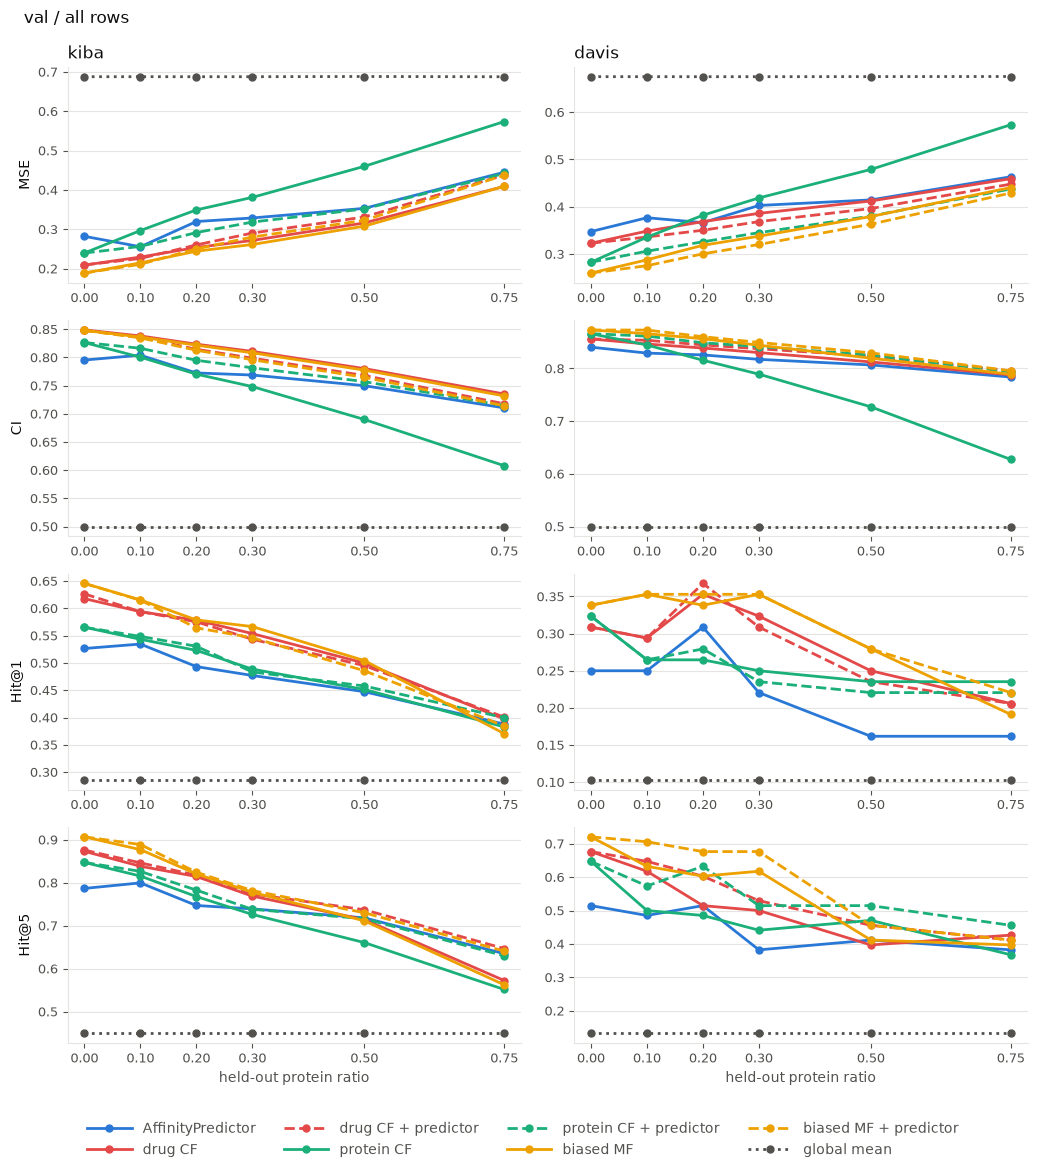

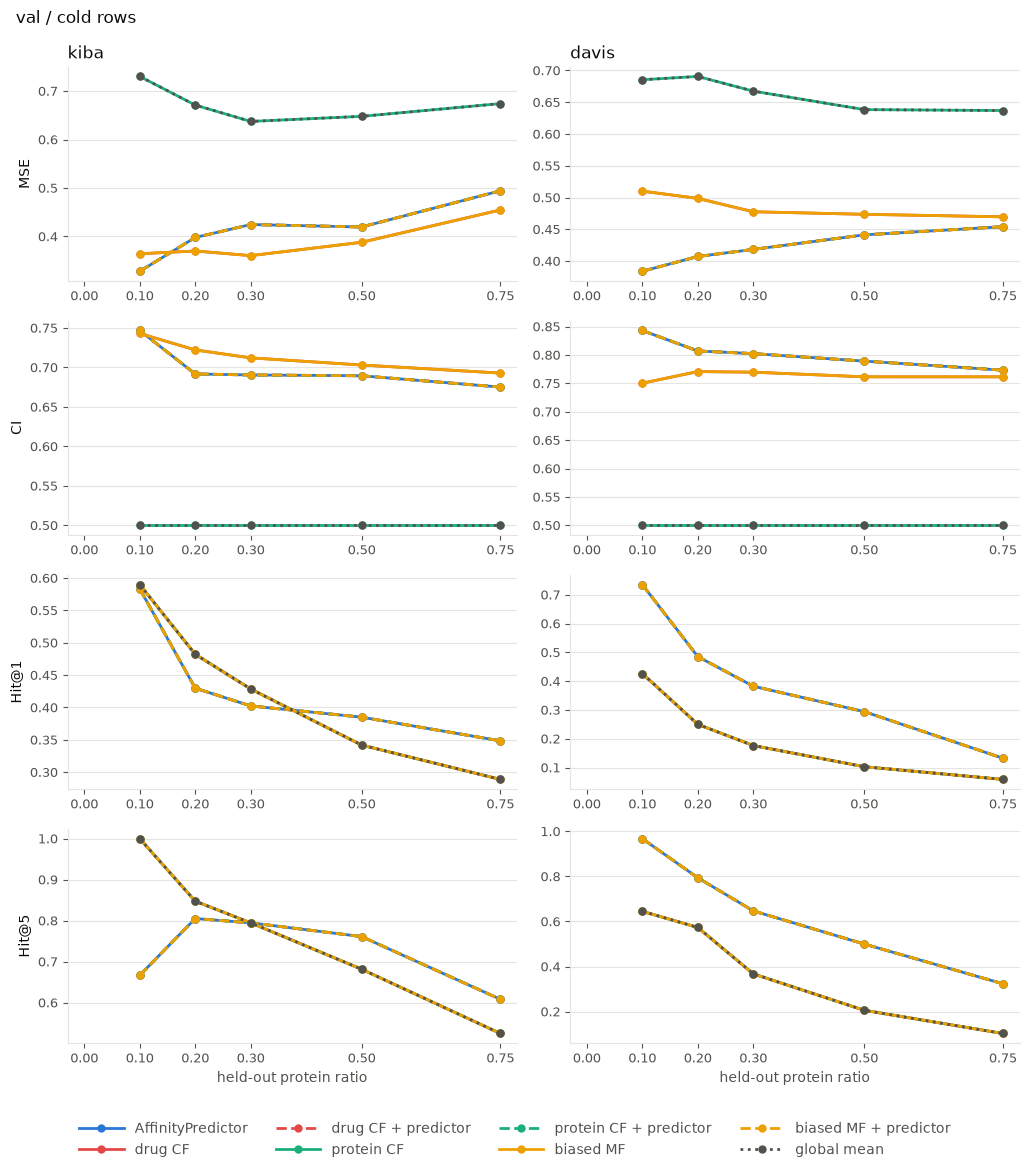

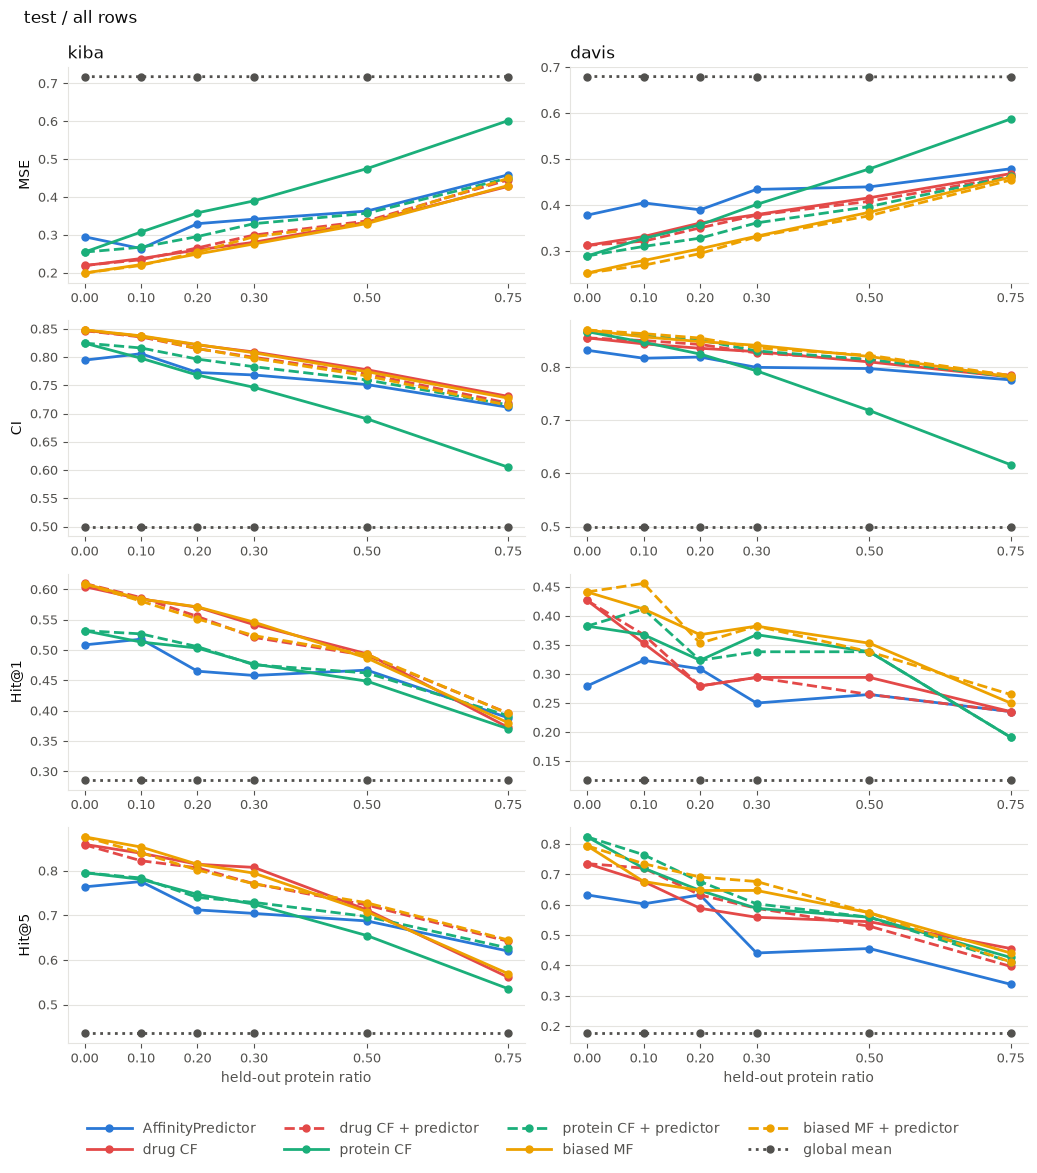

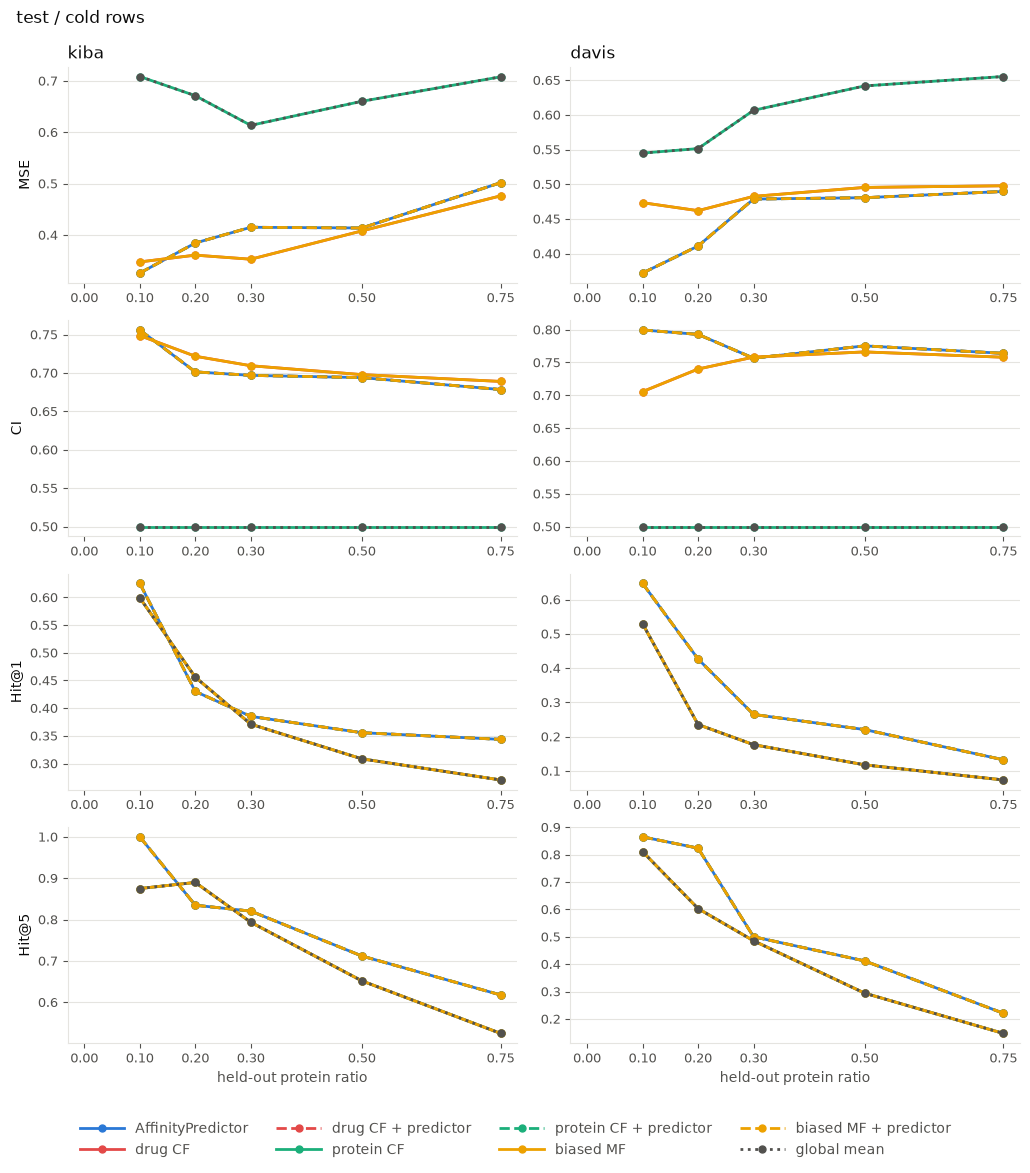

figures written to C:\Users\iamgr\Desktop\SC4020-Lab2\open_task\figures


In [11]:
CURVE_METRICS = ("MSE", "CI", "Hit@1", "Hit@5")
CURVE_GROUPS = ("all rows", "cold rows")

# Colour names the base model and the dash says the predictor filled its fallback rows, so
# the predictor's effect is the gap between a solid line and its own dash
SERIES = {
    MODEL_NAME: (PREDICTOR_COLOR, "-", "o"),
    "drug CF": (DRUG_CF_COLOR, "-", "o"),
    "drug CF + predictor": (DRUG_CF_COLOR, "--", "o"),
    "protein CF": (PROTEIN_CF_COLOR, "-", "o"),
    "protein CF + predictor": (PROTEIN_CF_COLOR, "--", "o"),
    "biased MF": (BIASED_MF_COLOR, "-", "o"),
    "biased MF + predictor": (BIASED_MF_COLOR, "--", "o"),
    "global mean": (MUTED_COLOR, ":", "o"),
}

measured = pd.DataFrame(measurements)


def draw_curves(panel, dataset, split, group, metric, series=None):
    """One metric against the holdout ratio, every model as its own line."""
    for model, (colour, style, marker) in (SERIES if series is None else series).items():
        curve = measured[
            (measured["dataset"] == dataset)
            & (measured["split"] == split)
            & (measured["group"] == group)
            & (measured["model"] == model)
        ].sort_values("holdout")
        panel.plot(
            curve["holdout"], curve[metric], label=model,
            color=colour, linestyle=style, linewidth=2, marker=marker, markersize=5)

    panel.set_xticks(HOLDOUTS)
    panel.set_xlim(min(HOLDOUTS) - 0.03, max(HOLDOUTS) + 0.03)
    panel.grid(axis="y", color=GRID_COLOR, linewidth=0.8)
    panel.set_axisbelow(True)
    panel.spines["top"].set_visible(False)
    panel.spines["right"].set_visible(False)
    panel.spines["left"].set_color(GRID_COLOR)
    panel.spines["bottom"].set_color(GRID_COLOR)
    panel.tick_params(colors=MUTED_COLOR, labelsize=9)


def add_legend(figure, panel, anchor):
    handles, labels = panel.get_legend_handles_labels()
    figure.legend(
        handles, labels, loc="lower center", ncol=4, frameon=False,
        labelcolor=MUTED_COLOR, handlelength=3.2, bbox_to_anchor=anchor)


for split in SPLITS:
    for group in CURVE_GROUPS:
        figure, panels = plt.subplots(
            len(CURVE_METRICS), len(DATASETS),
            figsize=(5.2 * len(DATASETS), 2.9 * len(CURVE_METRICS)), squeeze=False)

        for column, dataset in enumerate(DATASETS):
            for row, metric in enumerate(CURVE_METRICS):
                panel = panels[row][column]
                draw_curves(panel, dataset, split, group, metric)

                # Each dataset keeps its own y scale: pKd and the KIBA score are different
                # quantities, so a shared axis would imply a comparison that is not there
                if row == 0:
                    panel.set_title(dataset, color=TEXT_COLOR, loc="left")
                if row == len(CURVE_METRICS) - 1:
                    panel.set_xlabel("held-out protein ratio", color=MUTED_COLOR)
                if column == 0:
                    panel.set_ylabel(metric, color=TEXT_COLOR)

        add_legend(figure, panels[0][0], (0.5, -0.02))
        figure.suptitle(f"{split} / {group}", color=TEXT_COLOR, x=0.02, ha="left")
        figure.tight_layout(rect=(0, 0.04, 1, 0.99))

        figure.savefig(
            CURVE_PATTERN.format(split=split, group=group.replace(" ", "_")),
            dpi=150, bbox_inches="tight")
        plt.show()

# The same panels again one per file, each carrying its own legend, to be placed in the
# report singly. Too many to show inline, so these are written and closed.
for split in SPLITS:
    for group in CURVE_GROUPS:
        for dataset in DATASETS:
            for metric in CURVE_METRICS:
                figure, panel = plt.subplots(figsize=(6.4, 4.0))
                draw_curves(panel, dataset, split, group, metric)

                panel.set_title(
                    f"{dataset} / {split} / {group}", color=TEXT_COLOR, loc="left")
                panel.set_xlabel("held-out protein ratio", color=MUTED_COLOR)
                panel.set_ylabel(metric, color=TEXT_COLOR)
                add_legend(figure, panel, (0.5, -0.13))

                figure.savefig(
                    PANEL_PATTERN.format(
                        split=split, group=group.replace(" ", "_"), dataset=dataset,
                        metric=metric.lower().replace("@", "")),
                    dpi=150, bbox_inches="tight")
                plt.close(figure)

print("figures written to", FIGURE_DIR)

### Embeddings against Global Mean

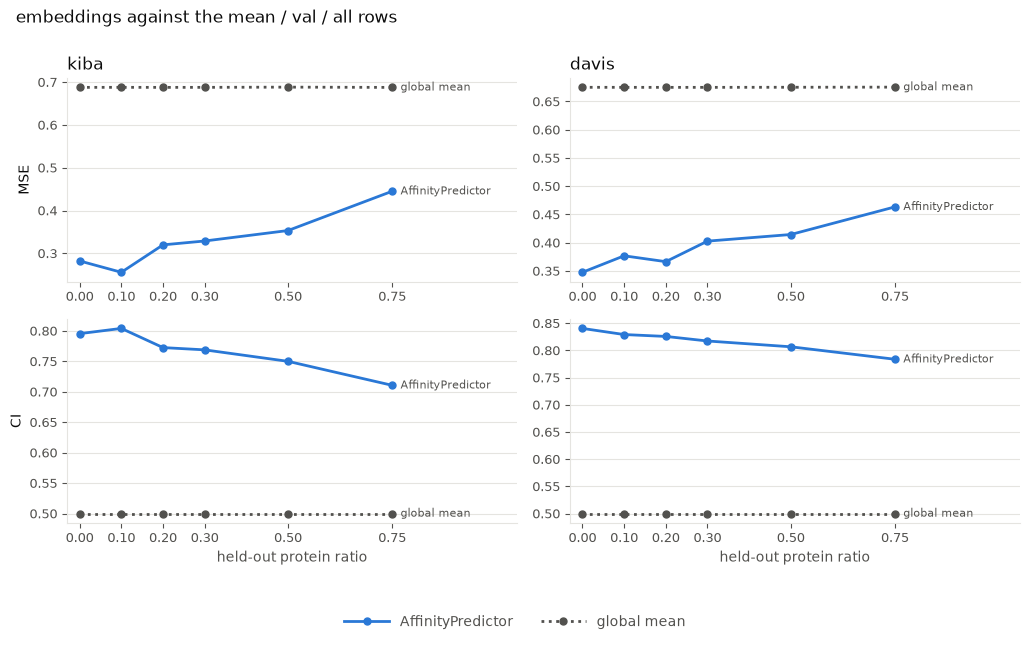

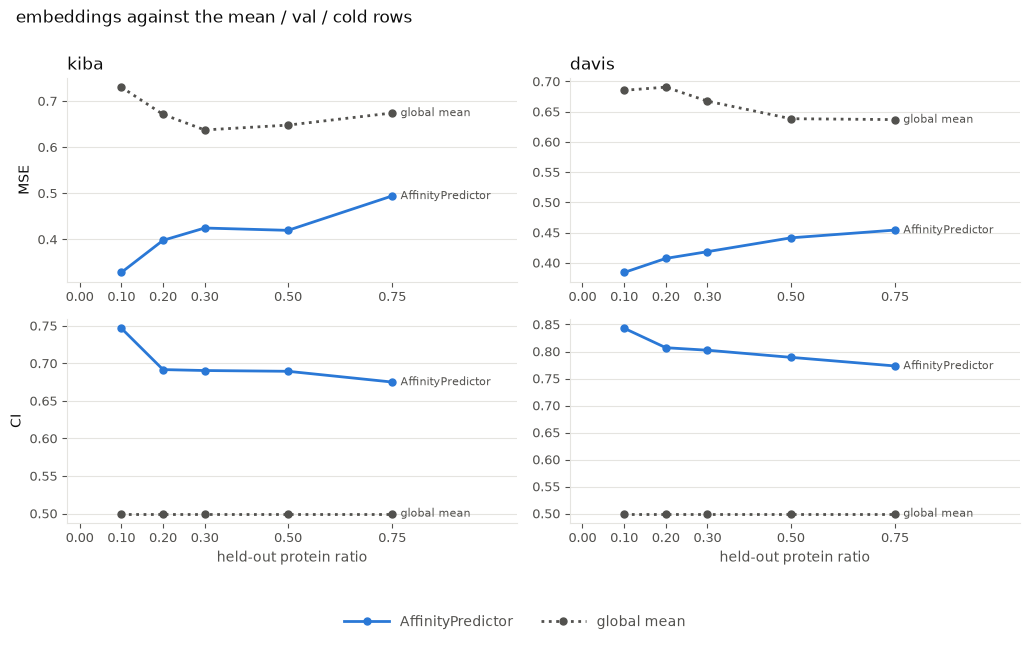

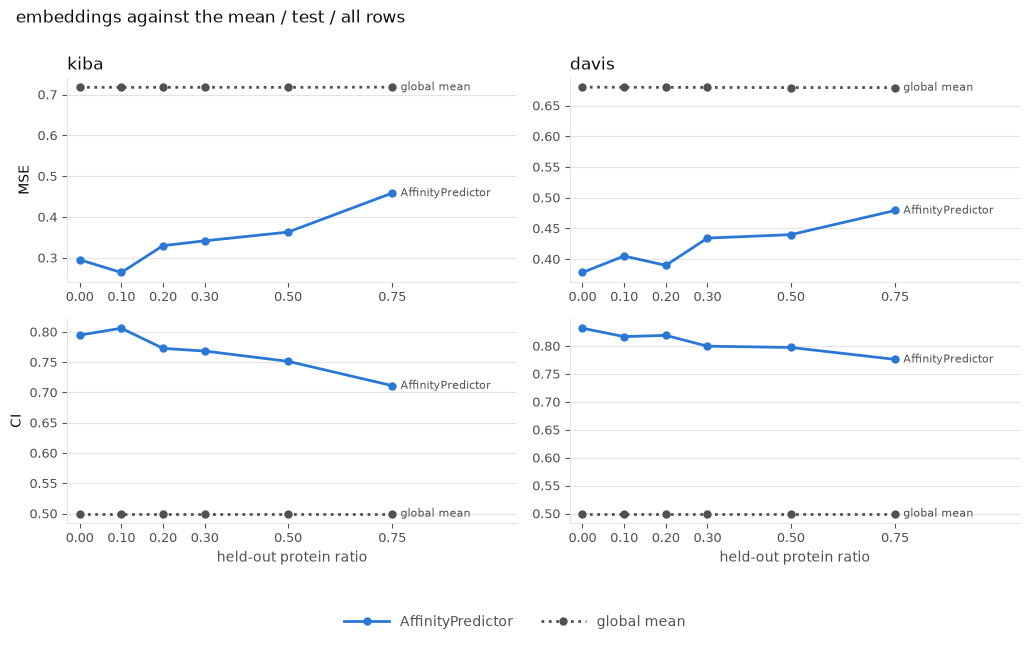

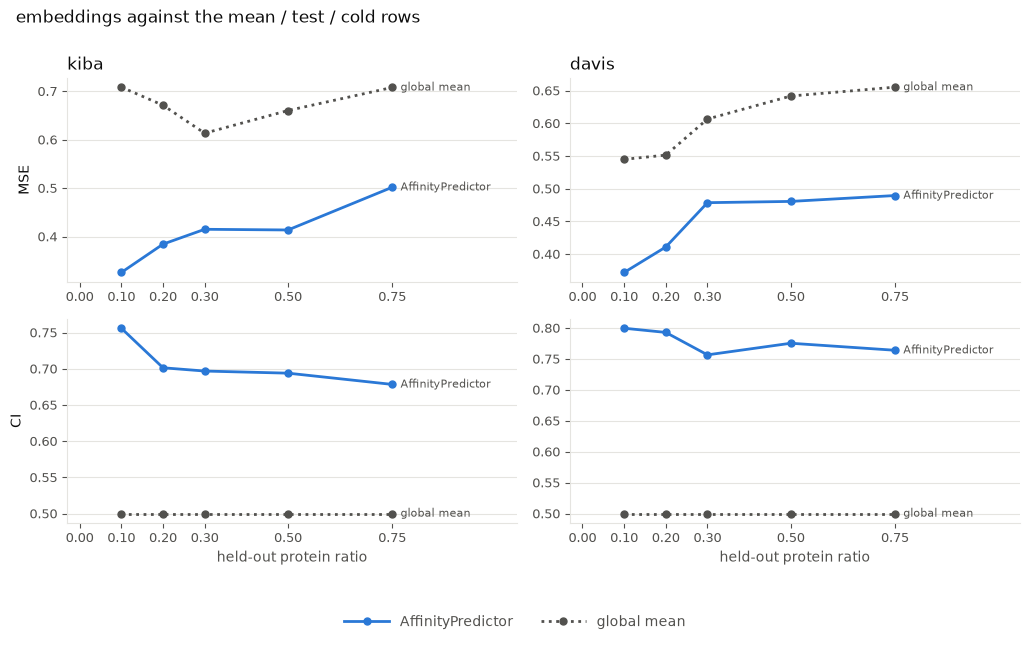

In [12]:
# Global mean is the no-information floor: one number for every pair, CI pinned at 0.5. The
# gap to it is what the drug and protein embeddings carry, and on cold rows the predictor
# has nothing but those embeddings to go on.
EMBEDDING_SERIES = {key: SERIES[key] for key in (MODEL_NAME, "global mean")}
EMBEDDING_METRICS = ("MSE", "CI")


def label_ends(panel, dataset, split, group, metric, series):
    """Direct labels, so a short series list is not told apart by colour alone."""
    for model, (colour, _, _marker) in series.items():
        curve = measured[
            (measured["dataset"] == dataset)
            & (measured["split"] == split)
            & (measured["group"] == group)
            & (measured["model"] == model)
        ].sort_values("holdout")
        panel.annotate(
            model, xy=(curve["holdout"].iloc[-1], curve[metric].iloc[-1]),
            xytext=(6, 0), textcoords="offset points",
            fontsize=8, color=MUTED_COLOR, va="center")

    panel.set_xlim(min(HOLDOUTS) - 0.03, max(HOLDOUTS) + 0.3)


for split in SPLITS:
    for group in CURVE_GROUPS:
        figure, panels = plt.subplots(
            len(EMBEDDING_METRICS), len(DATASETS),
            figsize=(5.2 * len(DATASETS), 3.1 * len(EMBEDDING_METRICS)), squeeze=False)

        for column, dataset in enumerate(DATASETS):
            for row, metric in enumerate(EMBEDDING_METRICS):
                panel = panels[row][column]
                draw_curves(panel, dataset, split, group, metric, EMBEDDING_SERIES)
                label_ends(panel, dataset, split, group, metric, EMBEDDING_SERIES)

                if row == 0:
                    panel.set_title(dataset, color=TEXT_COLOR, loc="left")
                if row == len(EMBEDDING_METRICS) - 1:
                    panel.set_xlabel("held-out protein ratio", color=MUTED_COLOR)
                if column == 0:
                    panel.set_ylabel(metric, color=TEXT_COLOR)

        add_legend(figure, panels[0][0], (0.5, -0.04))
        figure.suptitle(
            f"embeddings against the mean / {split} / {group}", color=TEXT_COLOR,
            x=0.02, ha="left")
        figure.tight_layout(rect=(0, 0.06, 1, 0.98))

        figure.savefig(
            FOCUS_PATTERN.format(
                name="embeddings", split=split, group=group.replace(" ", "_")),
            dpi=150, bbox_inches="tight")
        plt.show()

### AffinityPredictor vs Baseline CFs

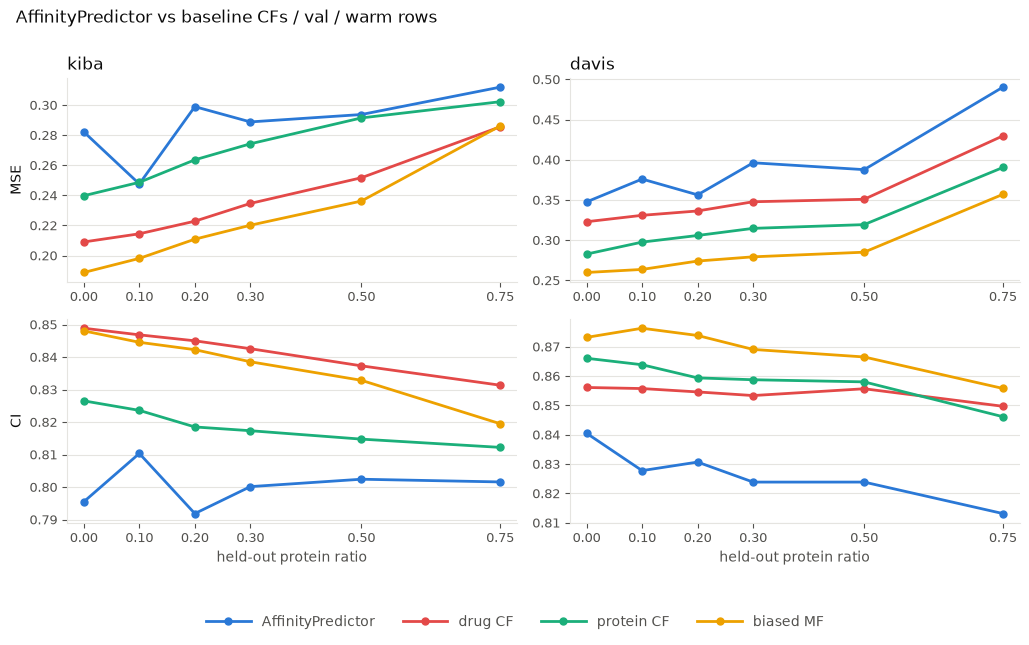

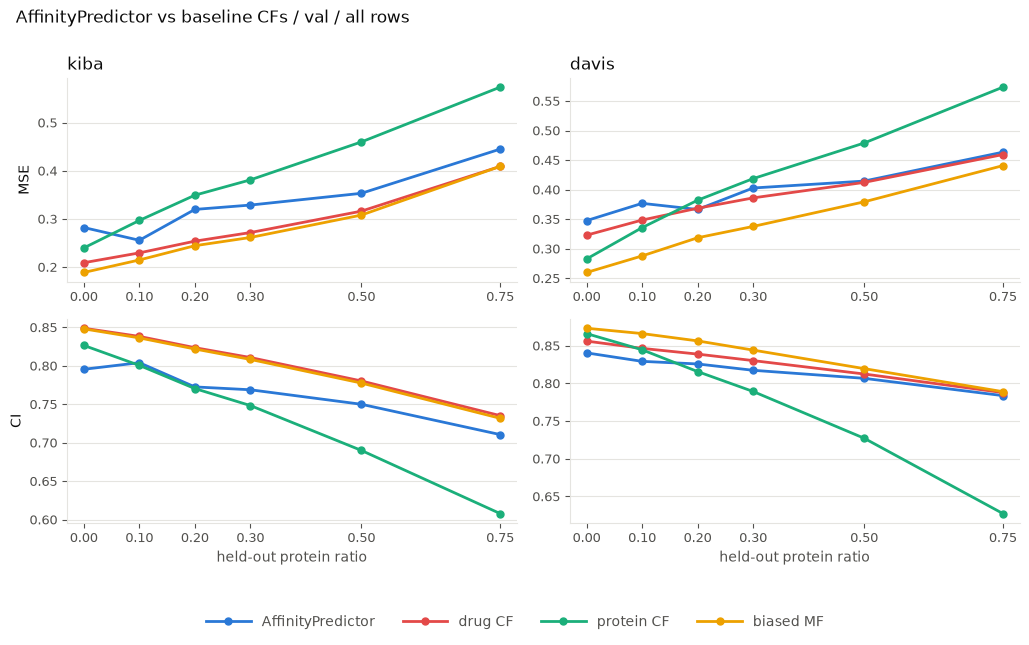

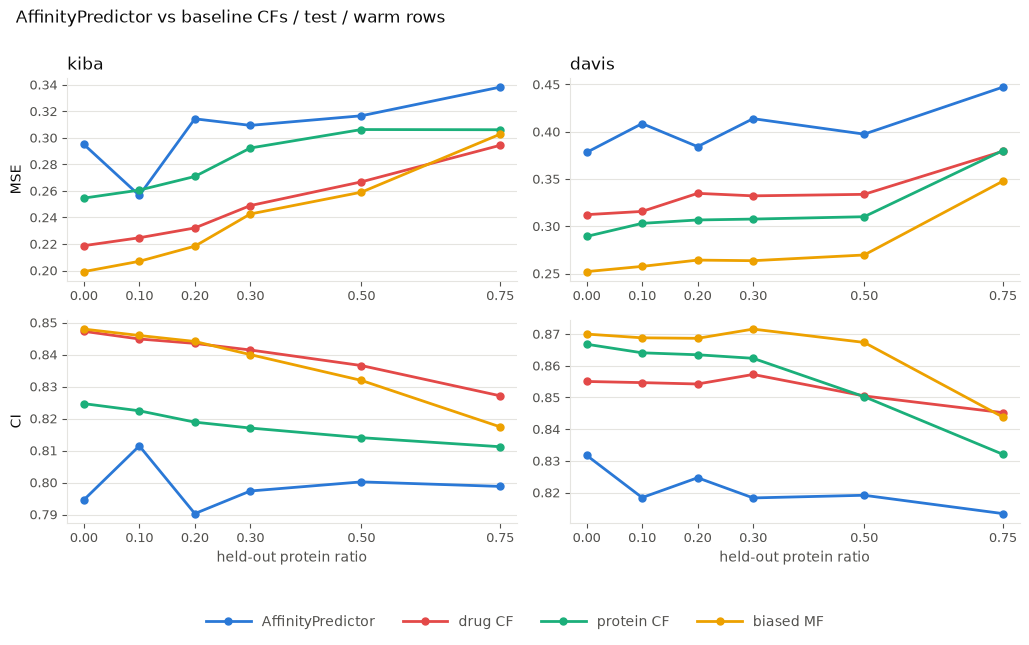

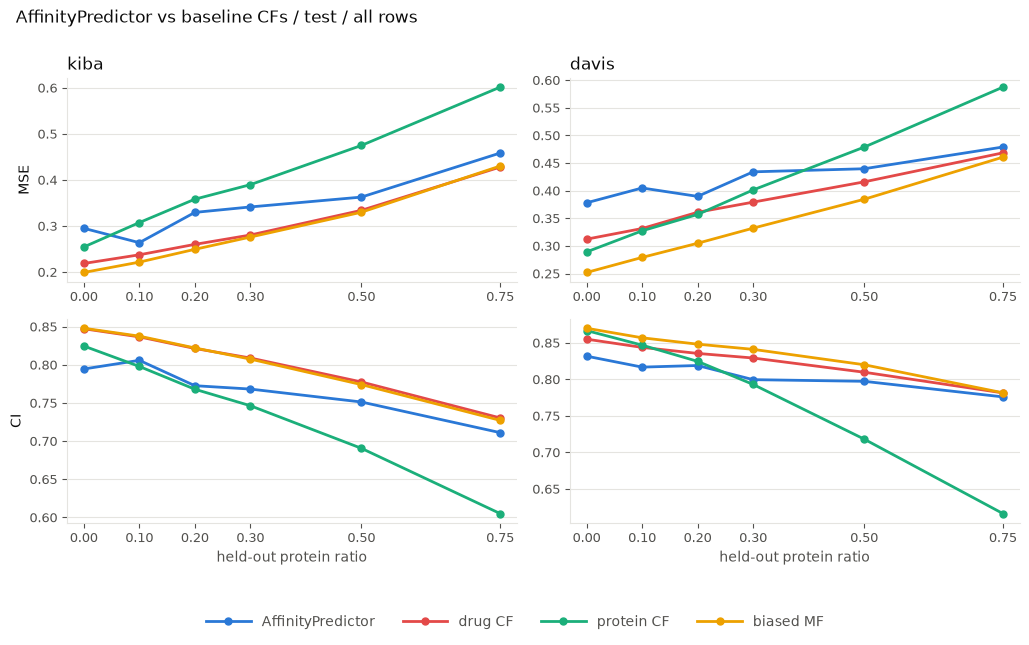

In [13]:
# Warm rows are the clean comparison: only there does every baseline run its own method.
# All rows add the cold rows, where protein CF returns the global mean and drug CF and
# biased MF both return the drug's training mean, so as the holdout grows those curves
# increasingly measure their fallback rather than CF.
BASELINE_SERIES = {
    key: SERIES[key] for key in (MODEL_NAME, "drug CF", "protein CF", "biased MF")}
BASELINE_METRICS = ("MSE", "CI")
BASELINE_GROUPS = ("warm rows", "all rows")

for split in SPLITS:
    for group in BASELINE_GROUPS:
        figure, panels = plt.subplots(
            len(BASELINE_METRICS), len(DATASETS),
            figsize=(5.2 * len(DATASETS), 3.1 * len(BASELINE_METRICS)), squeeze=False)

        for column, dataset in enumerate(DATASETS):
            for row, metric in enumerate(BASELINE_METRICS):
                panel = panels[row][column]
                draw_curves(panel, dataset, split, group, metric, BASELINE_SERIES)

                if row == 0:
                    panel.set_title(dataset, color=TEXT_COLOR, loc="left")
                if row == len(BASELINE_METRICS) - 1:
                    panel.set_xlabel("held-out protein ratio", color=MUTED_COLOR)
                if column == 0:
                    panel.set_ylabel(metric, color=TEXT_COLOR)

        add_legend(figure, panels[0][0], (0.5, -0.04))
        figure.suptitle(
            f"AffinityPredictor vs baseline CFs / {split} / {group}", color=TEXT_COLOR,
            x=0.02, ha="left")
        figure.tight_layout(rect=(0, 0.06, 1, 0.98))

        figure.savefig(
            FOCUS_PATTERN.format(
                name="baseline_cfs", split=split, group=group.replace(" ", "_")),
            dpi=150, bbox_inches="tight")
        plt.show()


### Predictor Fallback vs Mean Fallback

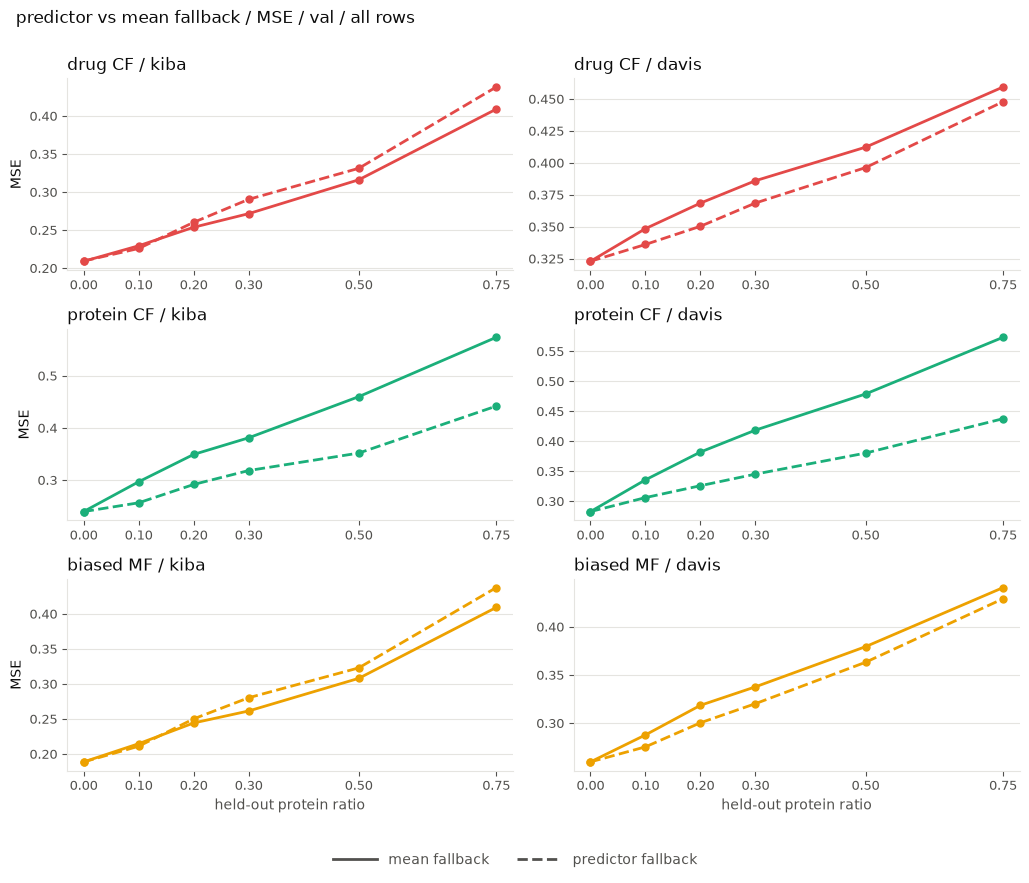

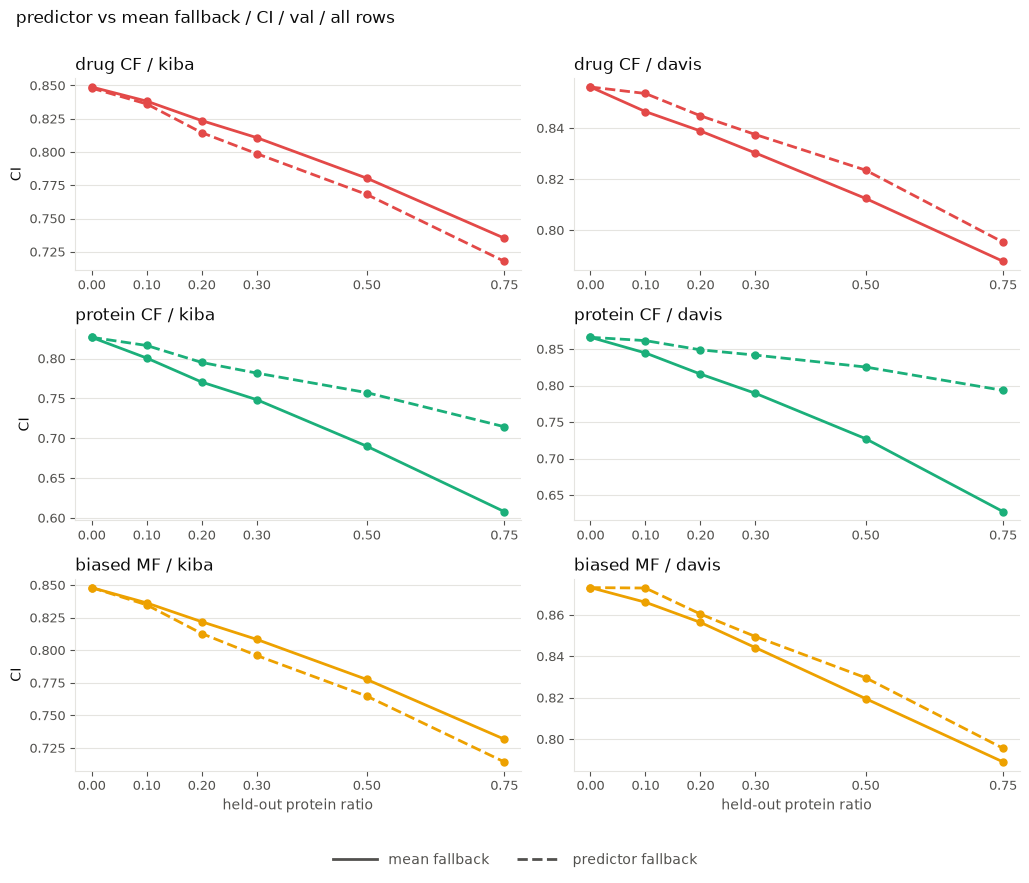

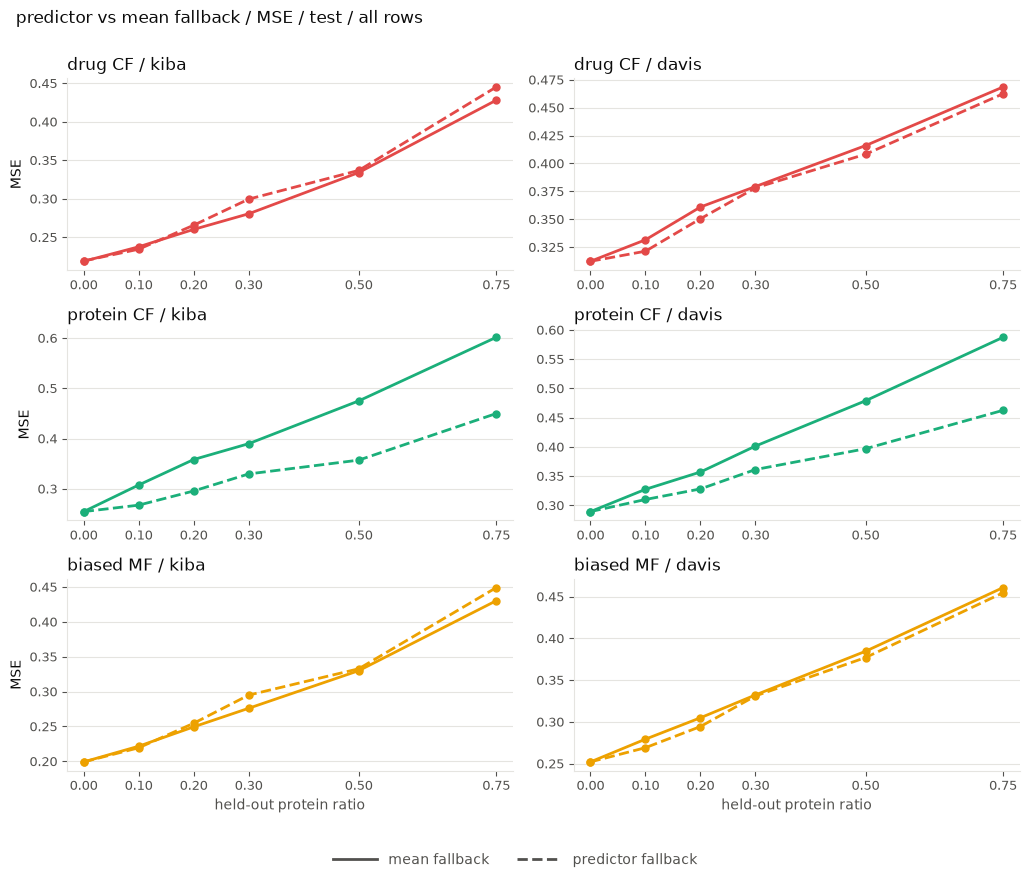

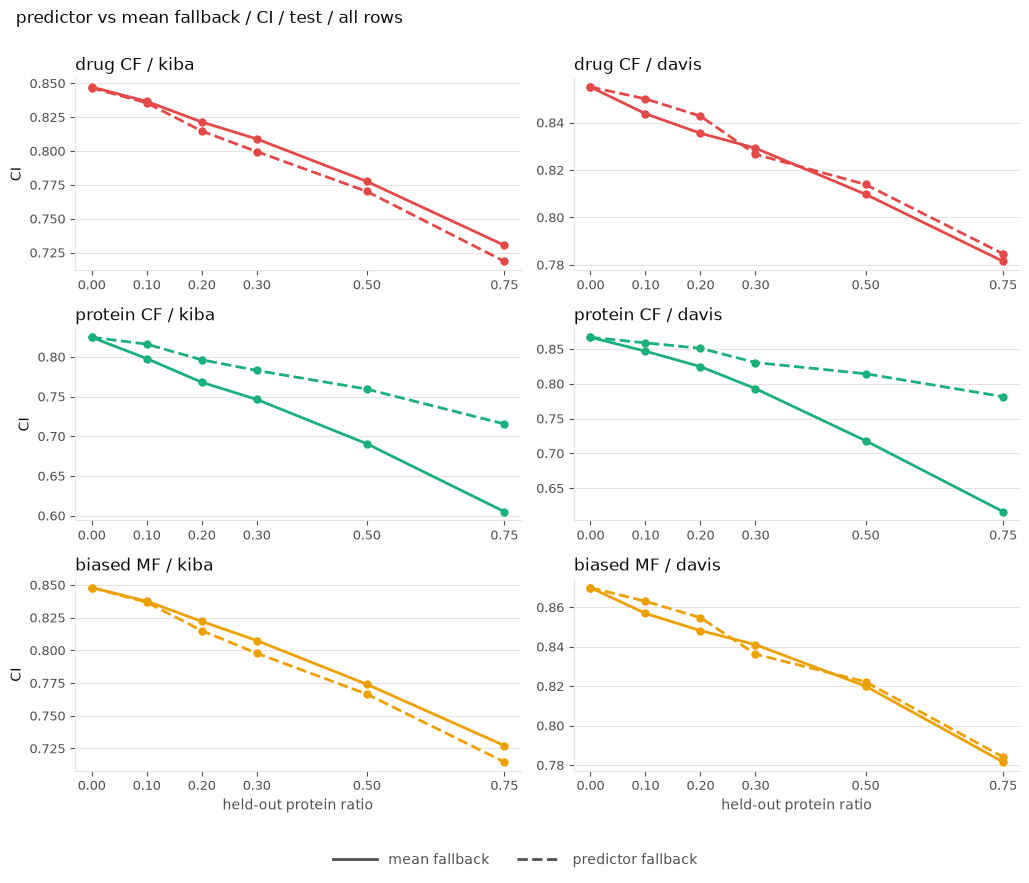

In [14]:
from matplotlib.lines import Line2D

# Each baseline against itself: solid is its own mean fallback, dashed is the predictor
# filling those rows, so the gap between the two is the predictor's whole contribution.
# Protein CF's fallback is the global mean; drug CF and biased MF fall back to the drug's
# training mean. All rows, because on warm rows the two lines barely differ and on cold
# rows every dashed line is the predictor itself.
FALLBACK_BASES = ("drug CF", "protein CF", "biased MF")
FALLBACK_METRICS = ("MSE", "CI")
FALLBACK_GROUP = "all rows"

for split in SPLITS:
    for metric in FALLBACK_METRICS:
        figure, panels = plt.subplots(
            len(FALLBACK_BASES), len(DATASETS),
            figsize=(5.2 * len(DATASETS), 2.9 * len(FALLBACK_BASES)), squeeze=False)

        for row, base in enumerate(FALLBACK_BASES):
            pair = {name: SERIES[name] for name in (base, f"{base} + predictor")}

            for column, dataset in enumerate(DATASETS):
                panel = panels[row][column]
                draw_curves(panel, dataset, split, FALLBACK_GROUP, metric, pair)

                panel.set_title(f"{base} / {dataset}", color=TEXT_COLOR, loc="left")
                if row == len(FALLBACK_BASES) - 1:
                    panel.set_xlabel("held-out protein ratio", color=MUTED_COLOR)
                if column == 0:
                    panel.set_ylabel(metric, color=TEXT_COLOR)

        # Colour already names the baseline in each title, so the legend explains the dash
        handles = [
            Line2D([], [], color=MUTED_COLOR, linestyle="-", linewidth=2),
            Line2D([], [], color=MUTED_COLOR, linestyle="--", linewidth=2),
        ]
        figure.legend(
            handles, ["mean fallback", "predictor fallback"], loc="lower center", ncol=2,
            frameon=False, labelcolor=MUTED_COLOR, handlelength=3.2,
            bbox_to_anchor=(0.5, -0.02))
        figure.suptitle(
            f"predictor vs mean fallback / {metric} / {split} / {FALLBACK_GROUP}",
            color=TEXT_COLOR, x=0.02, ha="left")
        figure.tight_layout(rect=(0, 0.04, 1, 0.98))

        figure.savefig(
            FOCUS_PATTERN.format(
                name=f"fallback_{metric.lower()}", split=split,
                group=FALLBACK_GROUP.replace(" ", "_")),
            dpi=150, bbox_inches="tight")
        plt.show()


### Recommendation Ranking as Proteins Are Held Out

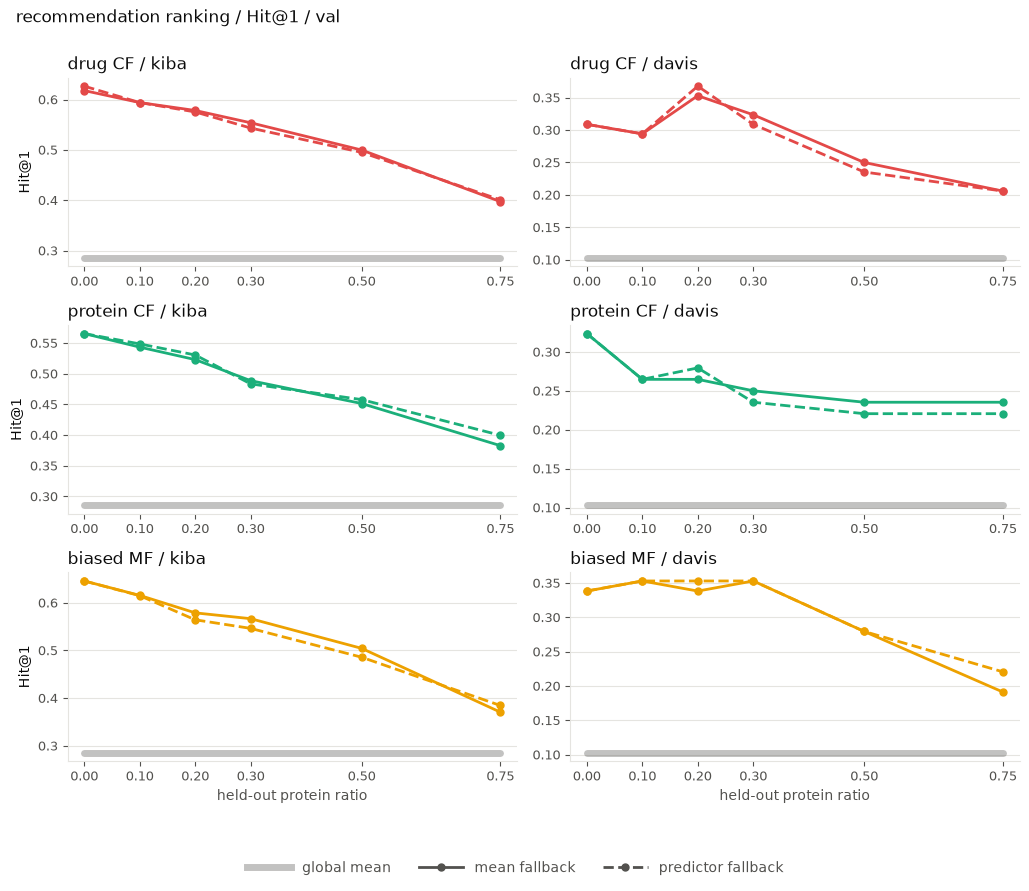

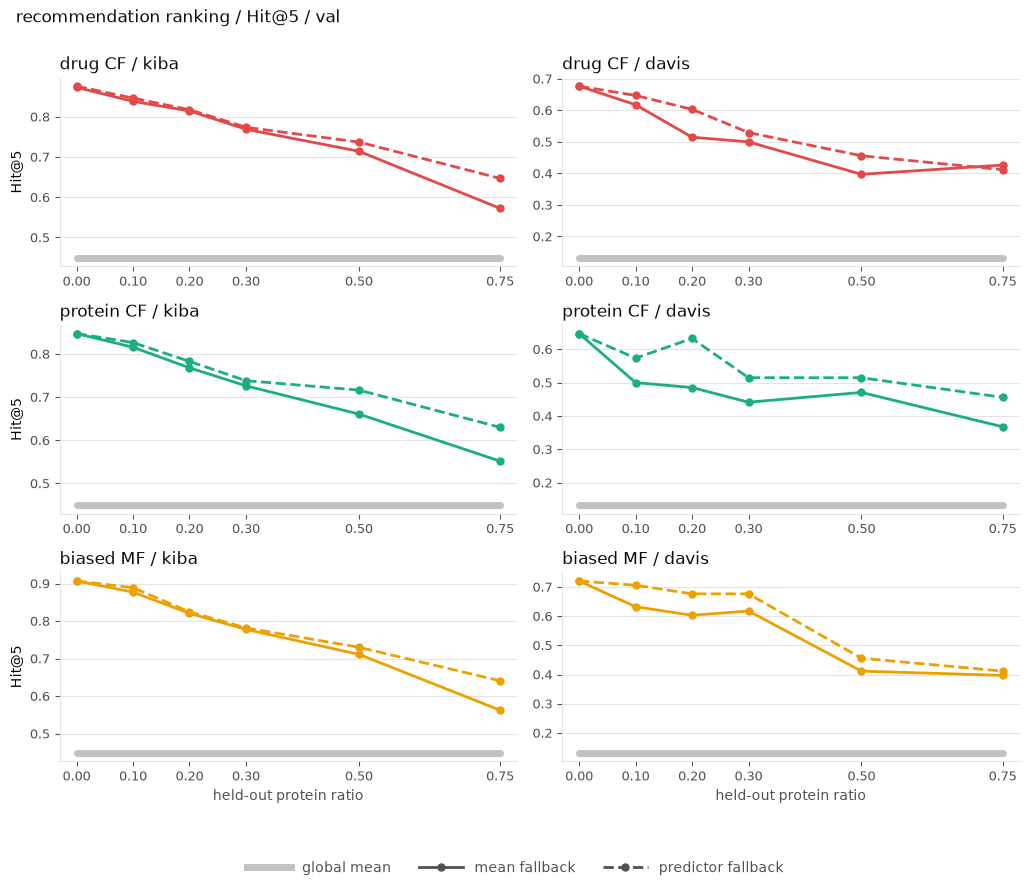

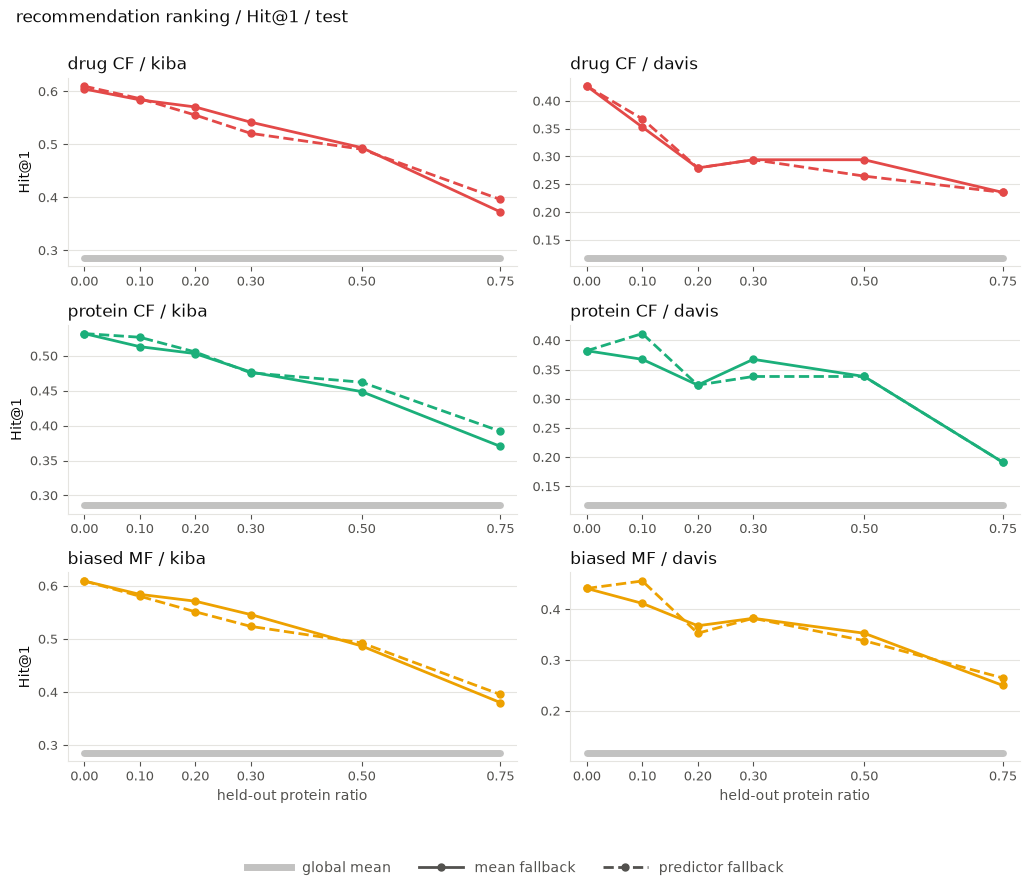

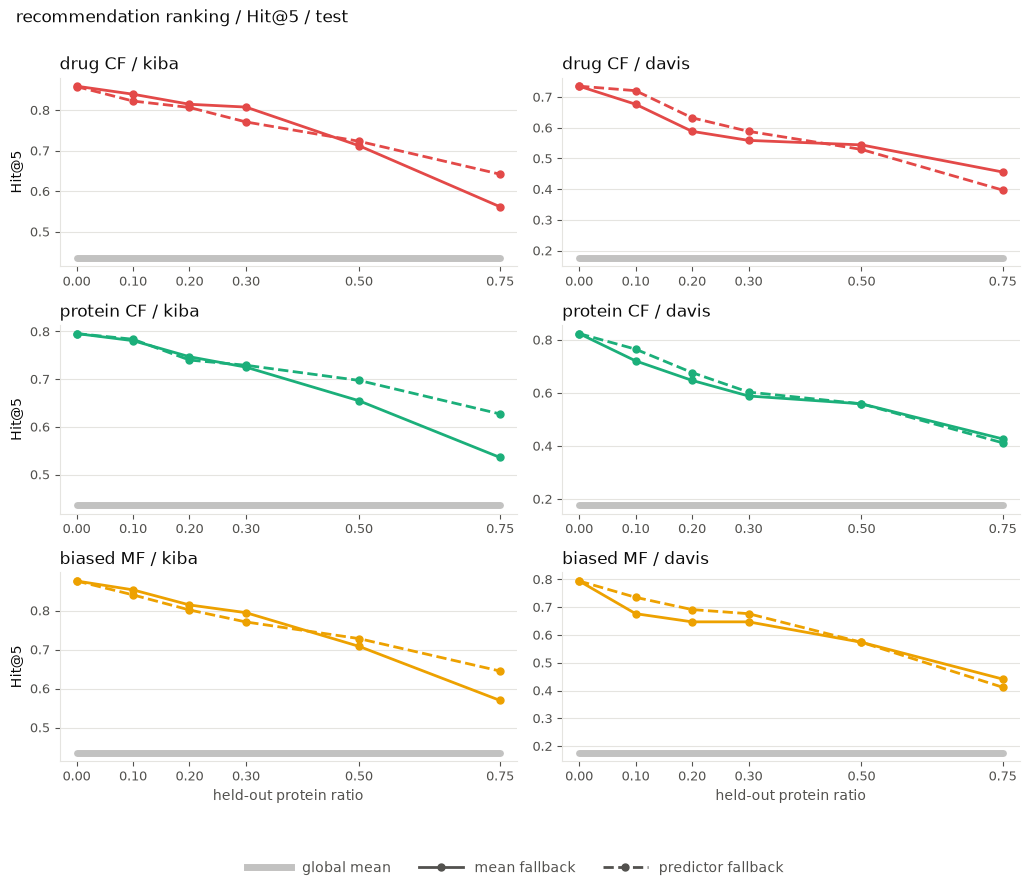

In [15]:
from matplotlib.lines import Line2D

# Hit@K is the ligand's own view: rank one ligand's candidate targets and ask whether its
# best target is in the top K. One row per baseline, so each panel holds a single pair:
# solid with its own mean fallback, dashed with the predictor filling those rows.
# The global mean is drawn thick underneath as the reference. It predicts one constant for
# every pair, so all of a ligand's candidates tie and hit_at_k's tie break by target
# sequence sets the order, making its score what alphabetical ordering earns, not skill.
# All rows, because val and test are never thinned, so the same ligands are ranked at every
# holdout. The warm subset loses ligands as the holdout grows, which would move the curves
# on its own.
RANKING_BASES = ("drug CF", "protein CF", "biased MF")
RANKING_METRICS = ("Hit@1", "Hit@5")
RANKING_GROUP = "all rows"


def draw_global_mean(panel, dataset, split, group, metric):
    """Drawn thick underneath: the score a model that cannot rank at all earns."""
    curve = measured[
        (measured["dataset"] == dataset)
        & (measured["split"] == split)
        & (measured["group"] == group)
        & (measured["model"] == "global mean")
    ].sort_values("holdout")
    panel.plot(
        curve["holdout"], curve[metric], label="global mean",
        color=MUTED_COLOR, linewidth=5, alpha=0.35, solid_capstyle="round", zorder=1)


def finish_ranking(figure, handles, labels, ncol, split, group, name, title):
    """Shared legend, title and file for the two ranking figures."""
    figure.legend(
        handles, labels, loc="lower center", ncol=ncol, frameon=False,
        labelcolor=MUTED_COLOR, handlelength=3.2, bbox_to_anchor=(0.5, -0.03))
    figure.suptitle(f"{title} / {split}", color=TEXT_COLOR, x=0.02, ha="left")
    figure.tight_layout(rect=(0, 0.05, 1, 0.98))

    figure.savefig(
        FOCUS_PATTERN.format(name=name, split=split, group=group.replace(" ", "_")),
        dpi=150, bbox_inches="tight")
    plt.show()


# Colour names the baseline in each panel title, so the legend explains only the dash
PAIR_HANDLES = [
    Line2D([], [], color=MUTED_COLOR, linewidth=5, alpha=0.35),
    Line2D([], [], color=MUTED_COLOR, linestyle="-", linewidth=2, marker="o", markersize=5),
    Line2D([], [], color=MUTED_COLOR, linestyle="--", linewidth=2, marker="o", markersize=5),
]
PAIR_LABELS = ["global mean", "mean fallback", "predictor fallback"]

for split in SPLITS:
    for metric in RANKING_METRICS:
        figure, panels = plt.subplots(
            len(RANKING_BASES), len(DATASETS),
            figsize=(5.2 * len(DATASETS), 2.9 * len(RANKING_BASES)), squeeze=False)

        for row, base in enumerate(RANKING_BASES):
            pair = {key: SERIES[key] for key in (base, f"{base} + predictor")}

            for column, dataset in enumerate(DATASETS):
                panel = panels[row][column]
                draw_global_mean(panel, dataset, split, RANKING_GROUP, metric)
                draw_curves(panel, dataset, split, RANKING_GROUP, metric, pair)

                panel.set_title(f"{base} / {dataset}", color=TEXT_COLOR, loc="left")
                if row == len(RANKING_BASES) - 1:
                    panel.set_xlabel("held-out protein ratio", color=MUTED_COLOR)
                if column == 0:
                    panel.set_ylabel(metric, color=TEXT_COLOR)

        finish_ranking(
            figure, PAIR_HANDLES, PAIR_LABELS, 3, split, RANKING_GROUP,
            f"recommendation_ranking_{metric.lower().replace('@', '')}",
            f"recommendation ranking / {metric}")


### Ranking Degrades to the Global Mean on Cold Rows

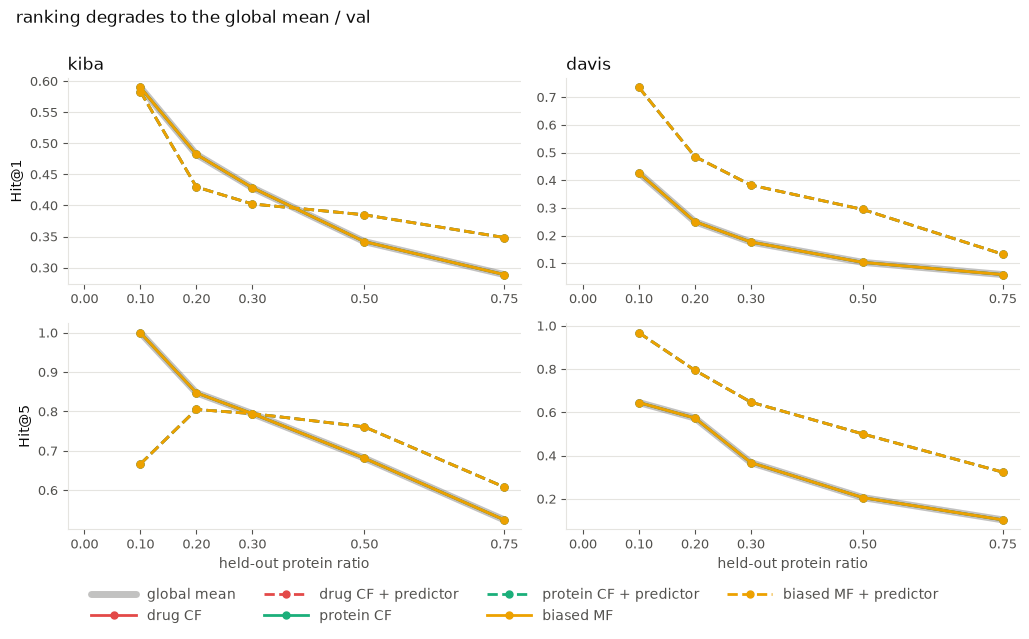

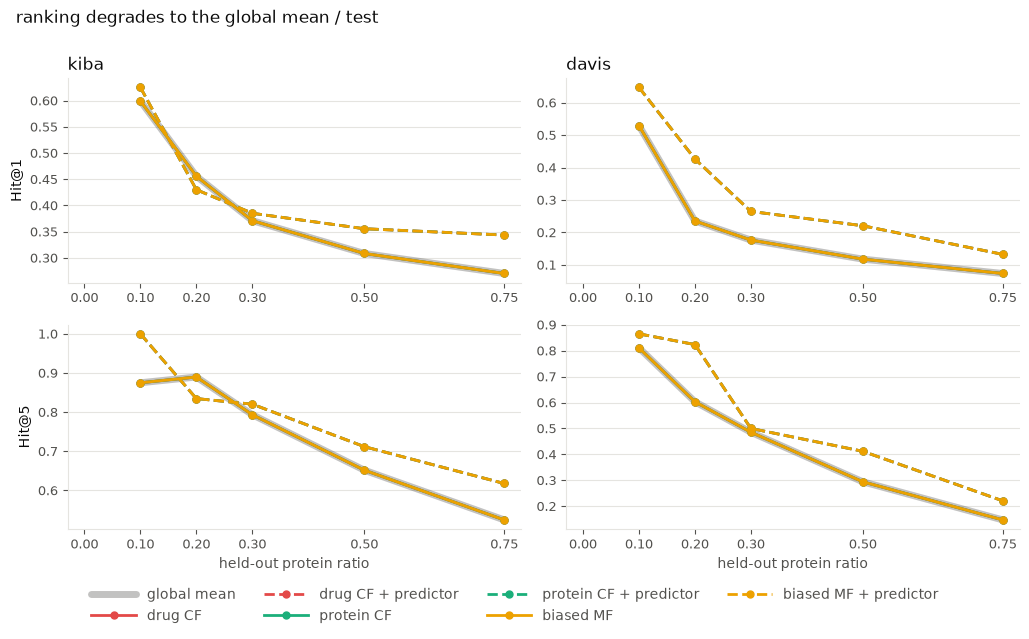

In [16]:
# Cold rows, where both halves collapse onto two paths, so one panel per metric shows it
# all. Every baseline predicts one constant per ligand there, so all three inherit the
# global mean's alphabetical ordering and score exactly what it scores; every fallback row
# is a cold row, so all three dashed lines are the predictor itself. The lines are left to
# overlap: the coincidence is the finding, and the last series drawn is the one on top.
COLD_SERIES = {
    key: SERIES[key]
    for base in RANKING_BASES
    for key in (base, f"{base} + predictor")
}

for split in SPLITS:
    figure, panels = plt.subplots(
        len(RANKING_METRICS), len(DATASETS),
        figsize=(5.2 * len(DATASETS), 3.1 * len(RANKING_METRICS)), squeeze=False)

    for column, dataset in enumerate(DATASETS):
        for row, metric in enumerate(RANKING_METRICS):
            panel = panels[row][column]
            draw_global_mean(panel, dataset, split, "cold rows", metric)
            draw_curves(panel, dataset, split, "cold rows", metric, COLD_SERIES)

            if row == 0:
                panel.set_title(dataset, color=TEXT_COLOR, loc="left")
            if row == len(RANKING_METRICS) - 1:
                panel.set_xlabel("held-out protein ratio", color=MUTED_COLOR)
            if column == 0:
                panel.set_ylabel(metric, color=TEXT_COLOR)

    handles, labels = panels[0][0].get_legend_handles_labels()
    finish_ranking(
        figure, handles, labels, 4, split, "cold rows", "ranking_degradation",
        "ranking degrades to the global mean")
